# 29 · Datasets et préparation du projet final — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch29_datasets/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 29.Q1 à 29.Q8, 29.R1 à 29.R3, 29.1, 29.2 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ | |
| A | 29.7 | Les datasets intégrés de scikit-learn, et une affirmation du livre à vérifier | 📦 | ★ | 15 |
|  | 29.8 | Prédire : le même modèle sur MNIST puis sur Fashion-MNIST | 🔮 | ★ | 10 |
|  | 29.9 | Prédire la chute d'accuracy en changeant de source de chiffres | 🔮 | ★ | 10 |
|  | 29.10 | torchvision.datasets et Hugging Face datasets : mêmes données, deux API | 📦 | ★★ | 25 |
|  | 29.11 | Explorer le Hugging Face Hub et OpenML : chercher, filtrer, lire la licence | 📦 | ★★ | 25 |
| B | 29.12 | Profil express d'un dataset inconnu | 📈 | ★★ | 20 |
|  | 29.13 | Un score trop beau pour être vrai : doublons entre entraînement et test | 🐛 | ★★ | 25 |
|  | 29.14 | Décalage de distribution : un modèle MNIST face aux chiffres de scikit-learn | 🔬 | ★★★ | 35 |
|  | 29.15 | Data card et script de téléchargement vérifié pour le projet final | 🛠️ | ★★★ | 60 |
|  | 29.16 | Le dataset piégé : trouver les huit défauts | 🏆 | ★★★ | 60 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Charger des datasets avec scikit-learn, torchvision et Hugging Face `datasets` (à une révision fixée), et chercher sur le Hub et OpenML en lisant la licence.
- Profiler un tableau inconnu, détecter les doublons qui fuient entre entraînement et test, et découper par groupes.
- Mesurer un décalage de distribution et ce que récupèrent une meilleure préparation et quelques exemples étiquetés.
- Écrire un téléchargement vérifié par SHA-256 et la data card du dataset de ton projet final.

**Rappel express.** Mesurer sur les données chargées, pas croire la description. Un dataset public n'est pas forcément libre : lire sa licence. Découper **avant** toute transformation ajustée sur les données, et **par groupes** quand des exemples sont liés. Mémoire d'un dataset d'images : $N \times H \times W \times C \times$ (octets par valeur).

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 29.1 et 29.2)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"B"`) ; plusieurs lettres : entre guillemets (`"ABD"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », l'estimation 🧮 29.3, la réflexion (🗣️ 29.4, ⚖️ 29.5, 📄 29.6) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
MB, GB = 1e6, 1e9                       # the conventions of the chapter: 1 MB = 10**6 bytes
MNIST_VALUES = 70_000 * 28 * 28         # uint8 values of MNIST (one channel)
CIFAR_VALUES = 60_000 * 32 * 32 * 3     # uint8 values of CIFAR-10 (three channels)
COUNTS_29_2 = {"A": 1200, "B": 600, "C": 200}
N_29_2 = sum(COUNTS_29_2.values())

**29.Q1 — Partir de l'existant : modèle pré-entraîné, dataset public ou collecte ?**

In [3]:
wb.record("29.Q1a", "B", mistakes={"la collecte est la voie la plus chère : le livre la garde pour la fin": "A", "entraîner de zéro coûte le plus de calcul et de données : c'est le dernier recours": "C"})
wb.record("29.Q1b", True, mistakes={"réutiliser un réseau déjà entraîné en l'ajustant à sa tâche, c'est la définition du transfer learning": False})
wb.record("29.Q1c", "C", mistakes={"toujours, non : un modèle pré-entraîné sur des données très différentes peut faire moins bien": "A", "un modèle pré-entraîné hérite des biais de ses données d'entraînement": "B"})
wb.record("29.Q1d", True, mistakes={"public ne veut pas dire libre : c'est la licence qui dit si l'usage commercial est permis": False})
wb.record("29.Q1e", "B", mistakes={"entraîner avant de regarder, c'est découvrir les défauts trop tard": "A", "l'augmentation multiplie les défauts au lieu de les révéler": "C"})

WB_ANSWER {"hash": "1e5564d9cee7c2081b420e77293956a63399de433e955c7fbb90be8eed1f99d3", "id": "29.Q1a", "kind": "str", "mistakes": {"0142ab5e7751f4e304dee8c7f210c302a52fb3fc03c60ca353264a21c8288aee": "entraîner de zéro coûte le plus de calcul et de données : c'est le dernier recours", "7fc8d0cf479e4c359f684bb5c925204a5f05f6f72c38e065bf502c7f3553d047": "la collecte est la voie la plus chère : le livre la garde pour la fin"}}
📝 Ex 29.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "4849fa6a5441847fc5df0b7dd31ac0989004c0fe0f07ea97ffdda66a22a4337d", "id": "29.Q1b", "kind": "bool", "mistakes": {"3a2cbe3b8d2d641573cc93865571a2ebfe7ab85a11414e21599bb933f811e6ac": "réutiliser un réseau déjà entraîné en l'ajustant à sa tâche, c'est la définition du transfer learning"}}
📝 Ex 29.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "23b488698a1ff5b9b98975378d7e233f02a89f191c1ffbd5f6fd503620f6839f", "id": "29.Q1c", "kind": "str", "mistakes": {"0c72c07978fca9369e38695e49f47773b631bd154c54839eb55f

**29.Q2 — Licences et restrictions d'usage : vrai ou faux**

In [4]:
wb.record("29.Q2a", True, mistakes={"CC BY n'interdit rien : elle demande seulement de citer la source": False})
wb.record("29.Q2b", False, mistakes={"NC, c'est « non commercial » : pas de produit vendu": True})
wb.record("29.Q2c", False, mistakes={"un prototype destiné à être vendu n'est pas de la recherche : la restriction s'applique": True})
wb.record("29.Q2d", False, mistakes={"la licence porte sur les droits de celui qui publie, pas sur le consentement des personnes photographiées": True})
wb.record("29.Q2e", True, mistakes={"publier des données personnelles ne les fait pas sortir du RGPD": False})

WB_ANSWER {"hash": "bf87fa262b946bf3eb8f7ca27d45a460f725698fbc8276e55b588d6d0690952e", "id": "29.Q2a", "kind": "bool", "mistakes": {"f0a155d93944382cffd41fcaea8983f4b7ae0c502e6cf1e4418af03e8ca44d3d": "CC BY n'interdit rien : elle demande seulement de citer la source"}}
📝 Ex 29.Q2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "799e993adadfe2f2f915881d46bafc37cec396ffcb496dc559412fd9f3f5a114", "id": "29.Q2b", "kind": "bool", "mistakes": {"e918b06522a39457afc9fd025e2dc603c7ae7a41f75447db61775654409a84a2": "NC, c'est « non commercial » : pas de produit vendu"}}
📝 Ex 29.Q2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "26656466361e9f39349c690bcd385a780a7474542d96bb60718387069c96ffb1", "id": "29.Q2c", "kind": "bool", "mistakes": {"0e1a7595859d4ccc2c68e0f880ebb0afc688643309c45799ede51522069cf862": "un prototype destiné à être vendu n'est pas de la recherche : la restriction s'applique"}}
📝 Ex 29.Q2c : réponse enregistrée (bool).
WB_ANSWER {"hash": "8aa42a97c7b0c7bdaa14e907ebd655dd6714

**29.Q3 — Les défauts qu'une inspection manuelle révèle**

In [5]:
wb.record("29.Q3a", "ABC", mistakes={"les poids d'un réseau ne sont pas un défaut des données": "ABCD",
          "il manque les fautes d'orthographe": "AB", "il manque les champs vides": "BC",
          "il manque les labels qui n'apparaissent qu'une fois": "AC"})
wb.record("29.Q3b", "B", mistakes={"un poids négatif est impossible : un nombre rond et absurde code souvent une absence": "A"})
wb.record("29.Q3c", False, mistakes={"isna() ne voit que NaN et None : −999 est un nombre comme un autre pour pandas": True})
wb.record("29.Q3d", "B", mistakes={"un diamètre en millimètres n'est pas manquant : isna() ne le voit pas": "A", "un diamètre en millimètres ne crée pas de ligne en double": "C"})
wb.record("29.Q3e", True, mistakes={"relis l'encadré sur les audits : même les jeux de test des benchmarks ont des labels faux": False})

WB_ANSWER {"hash": "63d2fc4c2b18c9fb380cfcbd5ee91acb247d82b1223fd0e349c7a2cf7e4cfc48", "id": "29.Q3a", "kind": "str", "mistakes": {"3699752ba60f19b2331782fa7690c33a61ab0e63bc3eb9dff77f271067fecc27": "les poids d'un réseau ne sont pas un défaut des données", "62b7acbaea2c71c46f0b3b50b678da0f39f58bb1241af4a92d67058d625611ea": "il manque les fautes d'orthographe", "80841fb4c94352c43aa402bbba9bc2f97708179533540d693c5249b75f92d035": "il manque les champs vides", "b80d18158df39f3f4a71d93d5070a212854067618f72f152c4556541528d21fa": "il manque les labels qui n'apparaissent qu'une fois"}}
📝 Ex 29.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "3f077b86c98378bcabdeb5eb1d4533da685b573b31d3ef2b4d89fa7b08389077", "id": "29.Q3b", "kind": "str", "mistakes": {"c78c81deb7148b9fb0f30c2dad1893923986b5392b137af91d4c817398396639": "un poids négatif est impossible : un nombre rond et absurde code souvent une absence"}}
📝 Ex 29.Q3b : réponse enregistrée (str).
WB_ANSWER {"hash": "eb342c60679df6d5b1cecc9b

**29.Q4 — MNIST et Fashion-MNIST : même format, difficulté différente**

In [6]:
wb.record("29.Q4a", 70000, mistakes={"c'est le seul jeu d'entraînement : ajoute les 10 000 images de test": 60000})
wb.record("29.Q4b", 28, mistakes={"784 est le nombre de pixels d'une image, pas son côté": 784})
wb.record("29.Q4c", 10, mistakes={"Fashion-MNIST garde les dix classes de MNIST, en vêtements": 9})
wb.record("29.Q4d", True, mistakes={"même format, mêmes formes de tableaux : seule la source change": False})
wb.record("29.Q4e", "B", mistakes={"Fashion-MNIST est en niveaux de gris, comme MNIST": "A", "il a exactement autant d'exemples que MNIST": "C"})

WB_ANSWER {"hash": "b13d5f1ce8cabcfd2c683f16de0b1fb6e8df455a1b060ac31438a4f4c1c911b0", "id": "29.Q4a", "kind": "int", "magnitude": 4, "mistakes": {"766286c1fa86004352b46a7c0ae455e6a5b9a7c5b23aebba227b7d13af988505": "c'est le seul jeu d'entraînement : ajoute les 10 000 images de test"}, "sign": 1}
📝 Ex 29.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "446648f3764e365f61ad1bcaec05ccf1d6c06a1f65e018f2f44782a1be3afde6", "id": "29.Q4b", "kind": "int", "magnitude": 1, "mistakes": {"0285bf60d3acc91e876274537687fb3720fbd50c5fa6e7837aed807bc5006f47": "784 est le nombre de pixels d'une image, pas son côté"}, "sign": 1}
📝 Ex 29.Q4b : réponse enregistrée (int).
WB_ANSWER {"hash": "d392d6c0a617a45b5ca1e837aae69c76799b328b5a3232a0bc1edc2fd94b9cc7", "id": "29.Q4c", "kind": "int", "magnitude": 1, "mistakes": {"5378dc66ee6c1b65cd93190ffbb8f23f69a57d586b4eb2894fab172fa29c597f": "Fashion-MNIST garde les dix classes de MNIST, en vêtements"}, "sign": 1}
📝 Ex 29.Q4c : réponse enregistrée (int).
WB_ANS

**29.Q5 — Les datasets de scikit-learn : lequel pour quelle tâche, et pourquoi Boston a disparu**

In [7]:
wb.record("29.Q5a", 1797, mistakes={"c'est le chiffre du livre : load_digits n'en livre qu'une partie": 5620})
wb.record("29.Q5b", "B", mistakes={"en 0.24, load_boston était encore là, sans même d'avertissement": "A", "scikit-learn n'a pas de version 2.0 : le retrait date de la 1.2": "C"})
wb.record("29.Q5c", "A", mistakes={"des données anciennes ne justifient pas un retrait : relis la description de la variable B": "B", "le problème n'est pas la justesse des prix, mais une variable construite sur un critère racial": "C"})
wb.record("29.Q5d", "C", mistakes={"Iris est une classification de fleurs": "A", "Breast Cancer est une classification de tumeurs": "B"})
wb.record("29.Q5e", False, mistakes={"Diabetes est un tableau de dix mesures numériques et une cible : pas un texte": True})

WB_ANSWER {"hash": "6c28d86d1c11d6783eaf73dfa4c5a24ff7c80beceb27864c2cee2136bb26faea", "id": "29.Q5a", "kind": "int", "magnitude": 3, "mistakes": {"c539aff25e632938dcefb9f380ed5fd9db84400cc1ec50a1d95d49d10c732717": "c'est le chiffre du livre : load_digits n'en livre qu'une partie"}, "sign": 1}
📝 Ex 29.Q5a : réponse enregistrée (int).
WB_ANSWER {"hash": "229d98a311a42163b021938df7bc38fdf7b6e5eb71949280284ed69f54367a15", "id": "29.Q5b", "kind": "str", "mistakes": {"8c1b07a3f03215e04be6d81317a1d0600d9878e9ae85c53483d9b7f788282d77": "scikit-learn n'a pas de version 2.0 : le retrait date de la 1.2", "f36b040e92f2a86fed085edd1e402581aa02e2ecc245b71eec17853e964554ae": "en 0.24, load_boston était encore là, sans même d'avertissement"}}
📝 Ex 29.Q5b : réponse enregistrée (str).
WB_ANSWER {"hash": "346bdebfb42ef12e8f0a8f66b5ac995f090e7553cad44fb734b2bf310dc78b26", "id": "29.Q5c", "kind": "str", "mistakes": {"b6aea42f9afbd1491a89d95619ff7b6b64f0628c7bc5511966232a614f994942": "des données anciennes

**29.Q6 — Des datasets de Keras à torchvision et Hugging Face**

In [8]:
wb.record("29.Q6a", "C", mistakes={"keras.datasets rend des tableaux NumPy, pas des DataFrames": "A", "le DataLoader est un objet de PyTorch, pas de Keras": "B"})
wb.record("29.Q6b", 60000, mistakes={"50 000, c'est l'entraînement seul : ajoute les 10 000 images de test": 50000})
wb.record("29.Q6c", "B", mistakes={"Keras livre IMDB déjà encodé : un entier par mot": "A"})
wb.record("29.Q6d", "B", mistakes={"torch.load relit un objet sauvegardé, il ne télécharge pas de dataset": "A"})
wb.record("29.Q6e", True, mistakes={"revision= désigne un commit précis du dépôt du dataset : la version est fixée": False})

WB_ANSWER {"hash": "1e0f5e2e66c73ad61d249073c49edbc506807e47daaf153aaeedb82527d2323e", "id": "29.Q6a", "kind": "str", "mistakes": {"113187ea515b8b145c510d4bb415b041945b826e66eb5caab5d18c0b9b66090f": "le DataLoader est un objet de PyTorch, pas de Keras", "1785ad475f3ad07c7efb383450149c881b248ff3452e4a01b4fa0b30664bf3e0": "keras.datasets rend des tableaux NumPy, pas des DataFrames"}}
📝 Ex 29.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "52887858bfe1e54fde5fc18c67609a142acc6b0c19ecbf9d04162cd650d47ea2", "id": "29.Q6b", "kind": "int", "magnitude": 4, "mistakes": {"fb27e20ab97626b8d5e747425d681d05ddf7455e2cfcf5fc523a6efc61c94958": "50 000, c'est l'entraînement seul : ajoute les 10 000 images de test"}, "sign": 1}
📝 Ex 29.Q6b : réponse enregistrée (int).
WB_ANSWER {"hash": "4241cf5816a6c88b66fe9cde9104faac8da0d22261fd49079bc33aafa402f778", "id": "29.Q6c", "kind": "str", "mistakes": {"567beb975328fcbf884727ee7261ee6f7554bcec2d23e56025f69021d489884a": "Keras livre IMDB déjà encodé : un 

**29.Q7 — Collections de datasets : UCI, Kaggle, OpenML, Hugging Face Hub et liens morts**

In [9]:
wb.record("29.Q7a", "ABC", mistakes={"deeplearning.net est un lien mort (encadré 🕰️ du §29.4)": "ABCD",
          "il manque OpenML": "AB", "il manque Kaggle": "AC", "il manque le Hugging Face Hub": "BC"})
wb.record("29.Q7b", False, mistakes={"l'outil kaggle lit une clé d'API personnelle, liée à un compte (encadré 🕰️ du §29.4)": True})
wb.record("29.Q7c", "C", mistakes={"torchvision fournit des datasets d'images, pas l'accès à OpenML": "A", "datasets charge le Hugging Face Hub, pas OpenML": "B"})
wb.record("29.Q7d", False, mistakes={"relis l'encadré 🕰️ du §29.4 : plusieurs liens du livre sont morts ou redirigés": True})
wb.record("29.Q7e", "A", mistakes={"une fiche modèle décrit un modèle, pas un dataset": "B", "le README d'un dépôt de code ne dit pas la licence ni les limites des données": "C"})

WB_ANSWER {"hash": "50b86f561da806322708a68278a7499c30bbf3bf568d6b83123b2c5659bbc7d9", "id": "29.Q7a", "kind": "str", "mistakes": {"5fcc8b5c548a612b11ad7d65547dd9311d52a46be0a2277ad21e24ab4e2bfc99": "il manque OpenML", "6b47368fbe36c9515e7156ac2a5d78fb2e68da97e71d1130c46d4a45409890ef": "il manque le Hugging Face Hub", "7b3e651c5b22e8ae28dfe362c98c2398ce65cc671c66d01248da15c9855581ca": "deeplearning.net est un lien mort (encadré 🕰️ du §29.4)", "7f7c39a29e00cc8e63f5827618af4fb82d717f7801cd27461f3a74035e5a5ade": "il manque Kaggle"}}
📝 Ex 29.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "d4fd6cf5a8a10987707cceb5680a2a6ead5399e5b45addb17f92ac2e8776cc7a", "id": "29.Q7b", "kind": "bool", "mistakes": {"59696059fb4728ad51bc0dd0700d019ccfd1392dcd071945882d45919c762448": "l'outil kaggle lit une clé d'API personnelle, liée à un compte (encadré 🕰️ du §29.4)"}}
📝 Ex 29.Q7b : réponse enregistrée (bool).
WB_ANSWER {"hash": "1a397cbbc6c8a8eab0ec8811ce5bd3f701ac7e6e5005e5028b9fc37c064c6778", "id":

**29.Q8 — Les « nouveaux » datasets de 2018 : tâches, tailles et retraits**

In [10]:
wb.record("29.Q8a", 9, mistakes={"Open Images en compte environ neuf millions, pas un": 1})
wb.record("29.Q8b", "AC", mistakes={"COCO est toujours disponible": "ABC", "Fashion-MNIST est toujours disponible": "ACD",
          "il manque 80 Million Tiny Images": "A", "il manque MS-Celeb-1M": "C"})
wb.record("29.Q8c", "A", mistakes={"LAION-6B n'existe pas : relis l'encadré 🕰️ du §29.5": "B", "il a été republié, nettoyé, en 2024": "C"})
wb.record("29.Q8d", "B", mistakes={"la licence de CelebA exclut l'usage commercial": "A"})
wb.record("29.Q8e", True, mistakes={"une copie ne lève ni le retrait ni ses raisons : l'utiliser reste un problème": False})

WB_ANSWER {"hash": "5a30347c691dbffb03a3f639ff66e8efc85226747200ecb2b792aa013b3f6a44", "id": "29.Q8a", "kind": "int", "magnitude": 0, "mistakes": {"318ccf013afc2185020bc55e48473d870b52dbbd8b1b739652f47a603ab5ef3b": "Open Images en compte environ neuf millions, pas un"}, "sign": 1}
📝 Ex 29.Q8a : réponse enregistrée (int).
WB_ANSWER {"hash": "2e127da017dae55628e2680a71bff7d910f3728317cbe9f91849f8efa107dab8", "id": "29.Q8b", "kind": "str", "mistakes": {"511da1c6a511e7f831a6fda0e9f1ba95453cc1009b66da050b07ab587dd9976b": "il manque MS-Celeb-1M", "7ad46481cf0b7cb5e6096bf1868276af71e4a14ab6a67107cb93c3f708c96c36": "Fashion-MNIST est toujours disponible", "9a66657c244ff41f99e044012fa58c5d893b9f7af8a02d2a82cf48f2ede95016": "COCO est toujours disponible", "a4d52653e28b488c112d8bd386d4c4b998d39a9e19f978f847a12176afe76566": "il manque 80 Million Tiny Images"}}
📝 Ex 29.Q8b : réponse enregistrée (str).
WB_ANSWER {"hash": "9b0109ad7889a2be0e27a81c919e608146543ba77b3c2054ea82780814b358ec", "id": "29.Q

**29.R1 — Ch. 28 : qui possède les droits d'une image de style ?**

In [11]:
wb.record("29.R1a", 2044, mistakes={"70 ans après 1973, puis le 1ᵉʳ janvier suivant : 2044, pas 2043": 2043})
wb.record("29.R1b", False, mistakes={"la directive de 2019 (art. 14) : une reproduction fidèle d'une œuvre du domaine public n'est pas protégée": True})
wb.record("29.R1c", False, mistakes={"le droit d'auteur protège des œuvres, pas un style": True})
wb.record("29.R1d", "A", mistakes={"les photos de scikit-learn sont sous CC BY 2.0 : il faut créditer leurs auteurs": "B"})
wb.record("29.R1e", 1961, mistakes={"1890 + 70 = 1960, puis le 1ᵉʳ janvier suivant": 1960})

WB_ANSWER {"hash": "91ca0e8a486170e7b2ee1644f3af015b959b42fbae5f2a8b12d015334b3c390b", "id": "29.R1a", "kind": "int", "magnitude": 3, "mistakes": {"3924ecef4e9174924d73342f0508bc1acd168cc975187fd921c3aabfa7334a0e": "70 ans après 1973, puis le 1ᵉʳ janvier suivant : 2044, pas 2043"}, "sign": 1}
📝 Ex 29.R1a : réponse enregistrée (int).
WB_ANSWER {"hash": "d982cd95858f624c54b7d70b70c4d5b84e111669c87a793bb5e7fdde19e082a8", "id": "29.R1b", "kind": "bool", "mistakes": {"35ee46d60e0b8919fe424be5edbde6cff61853605434120a6bca0f7c6f3b43fe": "la directive de 2019 (art. 14) : une reproduction fidèle d'une œuvre du domaine public n'est pas protégée"}}
📝 Ex 29.R1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0d8bc4f499920dab53bce2d086bb41aa1acefa37fdfe120590ea5201184c1054", "id": "29.R1c", "kind": "bool", "mistakes": {"c10985b44a2931035ea5fabf6e408519b1b7cc20cbaa325c219db11bfffe5dd3": "le droit d'auteur protège des œuvres, pas un style"}}
📝 Ex 29.R1c : réponse enregistrée (bool).
WB_ANSWER {"hash

**29.R2 — Ch. 26 : en RL, d'où viennent les données ?**

In [12]:
wb.record("29.R2a", "B", mistakes={"en RL, aucun dataset annoté : l'agent produit ses données en agissant": "A"})
wb.record("29.R2b", True, mistakes={"une autre politique visite d'autres états : les données changent avec elle": False})
wb.record("29.R2c", "A", mistakes={"le rejeu stocke des transitions vécues, pas des images annotées": "B", "les poids sont dans le réseau, pas dans la mémoire de rejeu": "C"})
wb.record("29.R2d", 16, mistakes={"4 × 4 cases, c'est 16 états ; 4, c'est le nombre d'actions": 4})
wb.record("29.R2e", False, mistakes={"les données d'un agent changent avec sa politique : un découpage figé n'a pas de sens": True})

WB_ANSWER {"hash": "3b192d98ccafca78a527c657a23722afae3718d7a9000a4cab9fc089b1a64415", "id": "29.R2a", "kind": "str", "mistakes": {"75c198b19524f11679549a05aabd921a1c5481a22683ed6826d72b60ebc077a6": "en RL, aucun dataset annoté : l'agent produit ses données en agissant"}}
📝 Ex 29.R2a : réponse enregistrée (str).
WB_ANSWER {"hash": "13de3976a8adf0c6fdbe23246bb70c8fc6d390ae5a7298a6b10fb30d9458da5e", "id": "29.R2b", "kind": "bool", "mistakes": {"f44cf0961818083a3d35dae88acea8722516adba6d488d8f77d56f4b39a7fea0": "une autre politique visite d'autres états : les données changent avec elle"}}
📝 Ex 29.R2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "663729115eda41a474afff45fd6af5cc19945b0e7e30cd97fd90951006133dfc", "id": "29.R2c", "kind": "str", "mistakes": {"b748edede4a2221a6b3675f24a21a7bb27bb9f3bdedafb923ff5525a05ba0c50": "les poids sont dans le réseau, pas dans la mémoire de rejeu", "c745f404de066c21a3eda57bcdad5bd87f700107eb7c66f84f9dcb687de2ce91": "le rejeu stocke des transitions vé

**29.R3 — Ch. 2 : biais d'échantillonnage — un dataset représente-t-il la population visée ?**

In [13]:
wb.record("29.R3a", 344, mistakes={"333, c'est après avoir retiré les lignes incomplètes : compte-les toutes": 333})
wb.record("29.R3b", 3, mistakes={"trois espèces (Adélie, Chinstrap, Gentoo) ; trois îles aussi": 2})
wb.record("29.R3c", "A", mistakes={"une erreur de mesure fausse chaque valeur, pas le choix des exemples": "B", "un modèle trop simple, c'est de l'underfitting": "C"})
wb.record("29.R3d", False, mistakes={"trois espèces, trois îles, trois saisons : ce n'est pas tous les manchots du monde": True})
wb.record("29.R3e", "A", mistakes={"l'overfitting concerne l'écart entre entraînement et test d'une même distribution": "B", "une fuite fait passer de l'information du test à l'entraînement": "C"})

WB_ANSWER {"hash": "4eaed3481c88668d9408437164e9f27f638c0b4123f5b151063438f3881d98a9", "id": "29.R3a", "kind": "int", "magnitude": 2, "mistakes": {"4f0745ce27cd72f72f3984d8791b0708006b3a511ca907f27f8551792cd1b0fd": "333, c'est après avoir retiré les lignes incomplètes : compte-les toutes"}, "sign": 1}
📝 Ex 29.R3a : réponse enregistrée (int).
WB_ANSWER {"hash": "22c0be565dad480aa517bb212347bd4406aa5b1e7d4cb70bd138fac2f2a80016", "id": "29.R3b", "kind": "int", "magnitude": 0, "mistakes": {"3f5c4c0710f44fe7e3a04aad7f89c1c3d53181c045e2b51ab2ab3e51b23e59b2": "trois espèces (Adélie, Chinstrap, Gentoo) ; trois îles aussi"}, "sign": 1}
📝 Ex 29.R3b : réponse enregistrée (int).
WB_ANSWER {"hash": "84a0eb22c0465a4d04b012386f430dcde176c03962efa0dc3afaad1666b26bcc", "id": "29.R3c", "kind": "str", "mistakes": {"1a63f4a7c9fc3a15ff07c508146da7a9b30e4e6dc6652692d4ac8d198148460c": "un modèle trop simple, c'est de l'underfitting", "755fac314fd5e6bcb9f3f1f86b063ac4ff783b25e61ab48cdec41f389049fa0b": "une er

**Ex 29.1 — Poids en mémoire de MNIST, Fashion-MNIST et CIFAR-10**

In [14]:
wb.record("29.1a", MNIST_VALUES / MB, decimals=2, mistakes={"compte les 70 000 images, pas seulement les 60 000 d'entraînement": 60_000 * 784 / MB,
          "1 Mo = 10**6 octets ici, pas 2**20": MNIST_VALUES / 2 ** 20})
wb.record("29.1b", 4 * MNIST_VALUES / MB, decimals=2, mistakes={"un float32 occupe 4 octets, pas 8": 8 * MNIST_VALUES / MB})
wb.record("29.1c", CIFAR_VALUES / MB, decimals=2, mistakes={"CIFAR-10 a trois canaux de couleur": CIFAR_VALUES / 3 / MB})
wb.record("29.1d", 4 * CIFAR_VALUES / GB, decimals=3, mistakes={"en float32, multiplie par 4 octets": CIFAR_VALUES / GB})
wb.record("29.1e", int(GB // (784 * 4)), mistakes={"en float32, chaque valeur occupe 4 octets": int(GB // 784),
          "arrondis vers le bas : une image incomplète ne tient pas": int(GB // (784 * 4)) + 1})
wb.record("29.1f", True, mistakes={"même nombre d'images, même taille, même type : même mémoire": False})

WB_ANSWER {"decimals": 2, "hash": "9b76e09ad3a4ed63f3818c502fec5b7d789c4d57ae6bc5e5b5194bd52b247874", "hash_coarse": "33daf663586298a8284a1c17850122757dc5674acd674a1fd8853b4fe2301778", "id": "29.1a", "kind": "float", "magnitude": 1, "mistakes": {"179f6b70cb8c5cbdb851107b8661bc27e3a79358af1c8f7df15aaaa8d0401e11": "1 Mo = 10**6 octets ici, pas 2**20", "3231f210a454303d3390ecb342a40d7e8f096a41da4cc0aee5bed969611b2a75": "compte les 70 000 images, pas seulement les 60 000 d'entraînement"}, "sign": 1}
📝 Ex 29.1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "0b2535992706519abb6f9c7d3b26eb1bac802c3c67a9c519945f28653bd012f2", "hash_coarse": "3a4168f051bde3fb9b10f85b70778e468c7826127cc9f8735f0634ff95feeff3", "id": "29.1b", "kind": "float", "magnitude": 2, "mistakes": {"95a8d067828d8fdf143ebea214926c7a3478da85f52ee241c3505d241e15a015": "un float32 occupe 4 octets, pas 8"}, "sign": 1}
📝 Ex 29.1b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals":

**Ex 29.2 — Découpage stratifié et référence « classe majoritaire »**

In [15]:
wb.record("29.2a", round(0.70 * COUNTS_29_2['C']), mistakes={"70 % des 200 exemples de C, pas 70 % du total": 1400})
wb.record("29.2b", round(0.15 * COUNTS_29_2['C']), mistakes={"15 % des 200 exemples de C, pas 15 % du total": 300})
wb.record("29.2c", COUNTS_29_2['A'] / N_29_2, decimals=2, mistakes={"la classe majoritaire est A : 1 200 sur 2 000": 0.30})
wb.record("29.2d", (COUNTS_29_2['A'] + COUNTS_29_2['B']) / N_29_2, decimals=2, mistakes={"c'est l'accuracy du modèle de c) : un modèle peut aussi avoir juste sur tous les B": 0.60,
          "il rate au moins tous les C, soit 10 % du total": 1.0})
wb.record("29.2e", 0.0, decimals=2, mistakes={"le modèle ne prédit jamais C : il n'en trouve aucun": 1.0})
wb.record("29.2f", True, mistakes={"stratifier, c'est garder les proportions des classes dans chaque partie": False})

WB_ANSWER {"hash": "7efdd0d0a336b2a302096dccc49fd7f338ecf5f58508436fd96e9a5e6e8cb1fb", "id": "29.2a", "kind": "int", "magnitude": 2, "mistakes": {"1d5b5af48e8723baf343f7a284a58e73ae0480009ad6aadfd014300139c071f1": "70 % des 200 exemples de C, pas 70 % du total"}, "sign": 1}
📝 Ex 29.2a : réponse enregistrée (int).
WB_ANSWER {"hash": "7e9163e48c12d16107ae318564f0923000726c9a85cb2d58b6a2f55bd73e5fc8", "id": "29.2b", "kind": "int", "magnitude": 1, "mistakes": {"c0f409877d8b026041f454f2fd8b1c457ed60e1a6b580dea3fac14e189c5242a": "15 % des 200 exemples de C, pas 15 % du total"}, "sign": 1}
📝 Ex 29.2b : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "4c1e3fa7a729e015f6e1e0987f994582006db8bf960c65bd8c2d1772acbf38b5", "hash_coarse": "4d31b8d5a68c374a96a1d1ce1b2041f244c589d54f4eb15930f51129bad9f7fb", "id": "29.2c", "kind": "float", "magnitude": -1, "mistakes": {"55404089f789b00858fc0ca7ddd87b087688146cee60bf36208e5786fafae91c": "la classe majoritaire est A : 1 200 sur 2 000"}, "sign

## Outils du notebook

La cellule suivante importe pandas et PyTorch et définit les petits outils des deux parties : `train_mlp` et `evaluate` (le petit réseau de 29.8, 29.9 et 29.14), `fine_tune`, `digits_naive`, `show_digits`, `online`, un Hub et un OpenML simulés pour 29.11 (`FakeHubApi`, `fake_fetch_openml`) et `check_card` pour la data card de 29.15. Lis leurs docstrings au besoin.

In [16]:
# Tools for the notebook exercises (parts A and B)
import copy
import hashlib
import re
import socket
import tempfile
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wb.nbtools import StopCheck, checked, filled, fr, returned, same, verdict

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:                       # a computer without PyTorch (Mac Intel): parts of this chapter need Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : 29.8, 29.9 et 29.14 se font sur Colab (00_setup/INSTALL_LOCAL.md).")

WORK_DIR = Path(tempfile.mkdtemp(prefix="wb_ch29_"))   # a temporary folder for the files the exercises write


def pct(x, digits=1):
    """A share written the French way: 0.734 -> '73,4 %'."""
    return f"{100 * x:.{digits}f}".replace(".", ",") + " %"


def online(host="huggingface.co", timeout=5.0):
    """True if `host` answers on port 443 (the live parts of 29.10 and 29.11 are skipped without a network)."""
    try:
        socket.create_connection((host, 443), timeout=timeout).close()
        return True
    except OSError:
        return False


def train_mlp(X, y, epochs=2, seed=0, batch_size=64, lr=1e-3):
    """The small network of 29.8, 29.9 and 29.14: 784-128-10 (ReLU), `epochs` epochs of Adam on uint8 images
    (N, 28, 28) divided by 255. Deterministic for a given seed."""
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, yt = torch.as_tensor(X, dtype=torch.float32) / 255.0, torch.as_tensor(y, dtype=torch.long)
    generator = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        order = torch.randperm(len(Xt), generator=generator)
        for i in range(0, len(Xt), batch_size):
            idx = order[i:i + batch_size]
            loss = F.cross_entropy(model(Xt[idx]), yt[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model.eval()


def evaluate(model, X, y):
    """(accuracy, mean confidence) of `model` on uint8 images X (N, 28, 28): the confidence of one image is its
    largest softmax probability."""
    with torch.no_grad():
        logits = model(torch.as_tensor(X, dtype=torch.float32) / 255.0)
    probs = F.softmax(logits, dim=1)
    return float((logits.argmax(1).numpy() == np.asarray(y)).mean()), float(probs.max(1).values.mean())


def fine_tune(model, X, y, steps=100, lr=1e-3):
    """A copy of `model` trained `steps` more steps of Adam on all of (X, y) at once (a few labelled examples)."""
    model = copy.deepcopy(model).train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, yt = torch.as_tensor(X, dtype=torch.float32) / 255.0, torch.as_tensor(y, dtype=torch.long)
    for _ in range(steps):
        loss = F.cross_entropy(model(Xt), yt)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model.eval()


def digits_naive(images):
    """The 8 x 8 digits of scikit-learn (values 0 to 16) enlarged as they are to 28 x 28, uint8 0 to 255 (29.9)."""
    t = torch.as_tensor(np.asarray(images), dtype=torch.float32)[:, None] / 16.0
    out = F.interpolate(t, size=(28, 28), mode="bilinear", align_corners=False)[:, 0] * 255.0
    return np.clip(np.rint(out.numpy()), 0, 255).astype(np.uint8)


def show_digits(rows, titles, n=8):
    """One row of n images (28 x 28) per array of `rows`, its title on the left."""
    fig, axes = plt.subplots(len(rows), n, figsize=(1.1 * n, 1.25 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (images, title) in enumerate(zip(rows, titles)):
        for c in range(n):
            axes[r, c].imshow(images[c], cmap="gray", vmin=0, vmax=255)
            axes[r, c].axis("off")
        axes[r, 0].set_title(title, fontsize=8, loc="left")
    plt.tight_layout()
    plt.show()


# 29.11: stand-ins for the Hugging Face Hub and OpenML, so that the checks never depend on the network
FAKE_HUB = [SimpleNamespace(id=i, downloads=d, tags=t) for i, d, t in [
    ("demo/penguins-clean", 950, ["task_categories:tabular-classification", "license:cc0-1.0"]),
    ("demo/penguins-raw", 120, ["license:cc-by-4.0"]),
    ("someone/penguins-images", 3400, ["license:cc-by-nc-4.0", "size_categories:1K<n<10K"]),
    ("other/penguin-sounds", 40, []),
    ("lab/penguins-gps", 610, ["license:odbl"]),
    ("demo/fruits", 5000, ["license:mit"]),
]]


class FakeHubApi:
    """Answers list_datasets(search=..., limit=..., sort="downloads") like HfApi, from FAKE_HUB (no network)."""
    def __init__(self):
        self.calls = []

    def list_datasets(self, search=None, limit=None, sort=None, **kwargs):
        self.calls.append({"search": search, "limit": limit, "sort": sort, **kwargs})
        rows = [r for r in FAKE_HUB if search is None or search.lower() in r.id.lower()]
        if sort == "downloads":
            rows = sorted(rows, key=lambda r: -r.downloads)
        return iter(rows[:limit] if limit else rows)


def fake_fetch_openml(data_id=None, as_frame=True, **kwargs):
    """Answers like sklearn.datasets.fetch_openml(data_id=42585, as_frame=True), from the workbook copy of Penguins."""
    from sklearn.utils import Bunch
    frame = wb.datasets.load_penguins().drop(columns=["year"], errors="ignore")
    details = {"id": str(data_id), "name": "penguins", "version": "1", "licence": "CC0",
               "default_target_attribute": "species", "original_data_url": "https://github.com/allisonhorst/palmerpenguins",
               "md5_checksum": "0d4936a104bb85ef5127a5a63dce81f9"}
    return Bunch(frame=frame, details=details, target_names=["species"])


def watch_leaks(fn, X, y, groups):
    """Run fn(X, y, groups) with spies on PCA and KNeighborsClassifier (looked up in the notebook's globals, as the
    learner's function does) and record which rows of X each fit and each score saw (29.13). Returns
    (result, events): events is a list of (kind, row indices or None), kind in "pca_fit", "knn_fit", "knn_score"."""
    g = globals()
    flat = np.asarray(X).reshape(len(X), -1).astype(np.uint8)
    index = {row.tobytes(): i for i, row in enumerate(flat)}

    def rows_of(A):
        A = np.asarray(A, dtype=float)
        if A.ndim < 2 or A.size // len(A) != flat.shape[1]:
            return None                                          # not raw pixels (already transformed)
        A = A.reshape(len(A), -1)
        scale = 255.0 if A.max() <= 1.0 + 1e-9 else 1.0
        found = [index.get(r.tobytes()) for r in np.clip(np.rint(A * scale), 0, 255).astype(np.uint8)]
        return None if any(f is None for f in found) else np.array(found)

    events, made = [], {}
    real_pca, real_knn = g["PCA"], g["KNeighborsClassifier"]

    def seen(A):
        return made[id(A)][1] if id(A) in made else rows_of(A)

    class SpyPCA(real_pca):
        def fit(self, A, y=None):
            events.append(("pca_fit", rows_of(A)))
            return super().fit(A, y)

        def fit_transform(self, A, y=None):
            events.append(("pca_fit", rows_of(A)))
            out = super().fit_transform(A, y)
            made[id(out)] = (out, rows_of(A))
            return out

        def transform(self, A):
            out = super().transform(A)
            made[id(out)] = (out, rows_of(A))
            return out

    class SpyKNN(real_knn):
        def fit(self, A, y):
            events.append(("knn_fit", seen(A)))
            return super().fit(A, y)

        def score(self, A, y, sample_weight=None):
            events.append(("knn_score", seen(A)))
            return super().score(A, y, sample_weight=sample_weight)

    g["PCA"], g["KNeighborsClassifier"] = SpyPCA, SpyKNN
    try:
        result = fn(X, y, groups)
    finally:
        g["PCA"], g["KNeighborsClassifier"] = real_pca, real_knn
    return result, events


# 29.15: the sections a data card must have (the sheet, « Au-delà du livre : documenter et télécharger »)
CARD_SECTIONS = ["Provenance", "Contenu", "Licence", "Usage prévu", "Limites et biais", "Téléchargement"]


def check_card(text):
    """The list of problems of a data card written in Markdown (empty when it is complete)."""
    problems = [f"section « ## {s} » absente" for s in CARD_SECTIONS
                if not re.search(rf"^##\s+{re.escape(s)}\s*$", text, flags=re.M)]
    if "..." in text:
        problems.append("il reste des « ... » à remplacer")
    if not re.search(r"\b[0-9a-f]{64}\b", text):
        problems.append("aucune somme de contrôle SHA-256 (64 caractères hexadécimaux) dans la carte")
    if not re.search(r"https?://", text):
        problems.append("aucune adresse (URL) de la source")
    return problems

## Partie A · Charger, chercher, comparer

Les datasets intégrés aux bibliothèques, deux sources d'images au même format, le Hugging Face Hub et OpenML. Chaque fois, la même discipline : mesurer sur les données chargées plutôt que croire la description, et noter d'où viennent les données et sous quelle licence.

### Ex 29.7 — Les datasets intégrés de scikit-learn, et une affirmation du livre à vérifier 📦 ★ ⏱️ 15 min
**Objectif :** inventorier les datasets intégrés de scikit-learn en mesurant les données chargées, et vérifier qu'un loader existe encore.  
**Prérequis :** ch. 15 (scikit-learn) · fiche §29.3.1 (encadrés ⚠️ et 🕰️) · **Parcours :** R, M, C

Le livre annonce 5 620 images pour Digits et liste Boston parmi les datasets de scikit-learn. Vérifie sur ta version.

**Contrat**
- `inventory_7()` : un `DataFrame`, une ligne par dataset de `SKLEARN_LOADERS_7` (dans cet ordre), colonnes `"dataset"`, `"exemples"`, `"variables"`, `"tache"` (`"classification"` ou `"régression"`, d'après `REGRESSION_7`) et `"classes"` (le nombre de labels distincts, 0 pour une régression). Tout se **mesure** sur `X, y = getattr(skd, loader)(return_X_y=True)`.
- `has_loader_7(name)` : `True` si `sklearn.datasets` fournit encore la fonction `name`, `False` sinon, sans lever d'erreur. Piège : pour un loader retiré, scikit-learn lève une `ImportError` explicative, pas une `AttributeError` ; `hasattr` ne suffit donc pas.

La cellule de vérification compare ta table aux mesures, puis te fait reporter :
a) le nombre d'images de Digits, mesuré par ta table ;
b) la part de la classe minoritaire de Breast Cancer, à 3 décimales (`minority_7`, à calculer) ;
c) ce que rend `has_loader_7("load_boston")`.

Dans tes notes : lis le message de l'`ImportError` de `load_boston` (`try: skd.load_boston() except ImportError as e: print(e)`). Que propose scikit-learn à la place ? Pourquoi une table mesurée vaut-elle mieux qu'une liste recopiée d'un livre ou d'une page web ?

In [17]:
from sklearn import datasets as skd

# The loaders to inventory (name -> function of sklearn.datasets); "diabetes" is a regression
SKLEARN_LOADERS_7 = {"iris": "load_iris", "digits": "load_digits", "wine": "load_wine",
                     "breast_cancer": "load_breast_cancer", "diabetes": "load_diabetes"}
REGRESSION_7 = {"diabetes"}

In [18]:
def inventory_7():
    """A DataFrame, one row per dataset of SKLEARN_LOADERS_7 (in this order), with the columns "dataset" (its name),
    "exemples", "variables", "tache" ("classification" or "régression", from REGRESSION_7) and "classes" (the number
    of distinct labels, 0 for a regression), measured on the loaded data (getattr(skd, loader)(return_X_y=True))."""
    rows = []
    for name, loader in SKLEARN_LOADERS_7.items():
        X, y = getattr(skd, loader)(return_X_y=True)
        regression = name in REGRESSION_7
        rows.append({"dataset": name, "exemples": X.shape[0], "variables": X.shape[1],
                     "tache": "régression" if regression else "classification",
                     "classes": 0 if regression else len(np.unique(y))})
    return pd.DataFrame(rows)


def has_loader_7(name):
    """True if sklearn.datasets still provides the function `name` (e.g. "load_iris"), False otherwise. Careful: for
    a loader that was removed, scikit-learn raises an ImportError (with an explanation), not an AttributeError."""
    try:
        return callable(getattr(skd, name))
    except (AttributeError, ImportError):
        return False


_, y_bc_7 = skd.load_breast_cancer(return_X_y=True)
minority_7 = round(float(np.bincount(y_bc_7).min() / len(y_bc_7)), 3)


with checked("29.7"):
    table_7 = inventory_7()
    if not returned("29.7", "inventory_7", table_7):
        raise StopCheck
    columns_7 = ["dataset", "exemples", "variables", "tache", "classes"]
    verdict("29.7", isinstance(table_7, pd.DataFrame) and list(table_7.columns) == columns_7,
            "un DataFrame aux cinq colonnes demandées.",
            f"attendu un DataFrame aux colonnes {columns_7}, reçu {list(getattr(table_7, 'columns', []))}.")
    want_7 = []
    for name_7, loader_7 in SKLEARN_LOADERS_7.items():
        X_w7, y_w7 = getattr(skd, loader_7)(return_X_y=True)
        reg_7 = name_7 in REGRESSION_7
        want_7.append([name_7, X_w7.shape[0], X_w7.shape[1], "régression" if reg_7 else "classification",
                       0 if reg_7 else len(np.unique(y_w7))])
    got_7 = table_7[columns_7].values.tolist() if list(table_7.columns) == columns_7 else []
    bad_7 = [w[0] for w, g in zip(want_7, got_7) if [str(v) for v in w] != [str(v) for v in g]]
    verdict("29.7", len(got_7) == len(want_7) and not bad_7, "les tailles, les tâches et les classes sont justes.",
            f"lignes fausses ou manquantes : {bad_7 or 'nombre de lignes'} (mesure sur X.shape et np.unique(y)).")
    verdict("29.7", has_loader_7("load_iris") is True and has_loader_7("fetch_openml") is True,
            "has_loader_7 reconnaît les fonctions présentes.", "has_loader_7('load_iris') devrait rendre True.")
    verdict("29.7", has_loader_7("load_nothing_7") is False, "has_loader_7 rend False pour un nom inconnu.",
            "has_loader_7('load_nothing_7') devrait rendre False, sans lever d'erreur.")
    wb.check("29.7a", int(table_7.set_index("dataset").loc["digits", "exemples"]), computed=True)
    try:
        boston_7 = has_loader_7("load_boston")
    except ImportError:
        print("❌ Ex 29.7 : has_loader_7('load_boston') laisse passer l'ImportError de scikit-learn : hasattr, ou un "
              "except AttributeError seul, ne suffit pas ; attrape aussi ImportError.")
        raise StopCheck
    wb.check("29.7c", boston_7, computed=True)
wb.check("29.7b", minority_7)

✅ Ex 29.7 : un DataFrame aux cinq colonnes demandées.
✅ Ex 29.7 : les tailles, les tâches et les classes sont justes.
✅ Ex 29.7 : has_loader_7 reconnaît les fonctions présentes.
✅ Ex 29.7 : has_loader_7 rend False pour un nom inconnu.
✅ Ex 29.7a : Bravo !
✅ Ex 29.7c : Bien joué !
✅ Ex 29.7b : Exact !


In [19]:
wb.record("29.7a", 1797, mistakes={"c'est le nombre du livre : mesure X.shape[0] sur les données chargées": 5620})
wb.record("29.7b", 0.373, decimals=3, mistakes={"c'est la part de la classe majoritaire : prends la plus petite": 0.627,
                                                "une part entre 0 et 1, pas un effectif": 212.0})
wb.record("29.7c", False, mistakes={"load_boston a été retiré en 1.2 : un ImportError doit donner False": True})

WB_ANSWER {"hash": "b818dfc36ea82adaefd5054bdbf69644cf51412168040086d4a5a35cae8a2b84", "id": "29.7a", "kind": "int", "magnitude": 3, "mistakes": {"5bd236292f0d966f597c434a17d5d7d9d53b8fa84fb9af38465819e478b6f67e": "c'est le nombre du livre : mesure X.shape[0] sur les données chargées"}, "sign": 1}
📝 Ex 29.7a : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "d03e18e893afa4ef9d3290eec7dcea0997044311265097f6e809db3d783bcbbf", "hash_coarse": "f57452aa269e3bbe6e73ec9c62b6fec9b84cde6aafe52e3d8aaf1c2044aa7e02", "id": "29.7b", "kind": "float", "magnitude": -1, "mistakes": {"dcd68309677cf64f74957c4bea9daf5238906a50862da3f239dfe3b7a68fa555": "une part entre 0 et 1, pas un effectif", "dda1460ee405d6c060ac62f2887c3af392ea715fd02a23fd8c0ccb3bd3539d6e": "c'est la part de la classe majoritaire : prends la plus petite"}, "sign": 1}
📝 Ex 29.7b : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"hash": "208a58c110baab5b6351f3f8dbaa890b36865dc9b798320ddc9742bff0ed566b", "id": "29.7c",

### Ex 29.8 — Prédire : le même modèle sur MNIST puis sur Fashion-MNIST 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que coûte le passage de MNIST à Fashion-MNIST à un même petit réseau, et ce que fait un modèle de chiffres face à des vêtements.  
**Prérequis :** Ex 29.7 · fiche §29.2 · **Fil rouge :** MNIST · **Parcours :** R, M, C

La cellule suivante entraîne deux fois le même petit réseau dense (784-128-10, deux epochs d'Adam sur 10 000 images, `train_mlp` dans les outils) : `MODEL_M` sur MNIST, `MODEL_F` sur Fashion-MNIST. Même format, même code, seule la source change. Elle n'affiche rien.

**Avant d'exécuter l'expérience**, écris tes trois prédictions :
a) l'accuracy de test de `MODEL_M` sur MNIST : `"A"` moins de 0,90, `"B"` de 0,90 à 0,97, `"C"` plus de 0,97 ;
b) les points d'accuracy perdus par `MODEL_F` sur Fashion-MNIST par rapport à a) : `"A"` moins de 5, `"B"` de 5 à 15, `"C"` plus de 15 ;
c) l'accuracy de `MODEL_M` (entraîné sur des chiffres) sur le test de Fashion-MNIST : `"A"` moins de 0,2, `"B"` de 0,2 à 0,5, `"C"` plus de 0,5.

La cellule d'expérience n'affiche rien tant que tes trois prédictions ne sont pas écrites.

In [20]:
# The same small network (784-128-10, two epochs of Adam on 10 000 training images, train_mlp in the tools) trained
# twice: on MNIST, then on Fashion-MNIST. Nothing is printed here: the accuracies come after your predictions.
XM_TRAIN, YM_TRAIN = wb.datasets.load_mnist("train", 10_000)
XM_TEST, YM_TEST = wb.datasets.load_mnist("test")
XF_TRAIN, YF_TRAIN = wb.datasets.load_fashion_mnist("train", 10_000)
XF_TEST, YF_TEST = wb.datasets.load_fashion_mnist("test")
MODEL_M = train_mlp(XM_TRAIN, YM_TRAIN) if torch is not None else None
MODEL_F = train_mlp(XF_TRAIN, YF_TRAIN) if torch is not None else None

In [21]:
mnist_8, drop_8, crossed_8 = "B", "B", "A"

In [22]:
wb.record("29.8a", "B", mistakes={"deux epochs sur 10 000 images, un petit réseau dense : on n'atteint pas les 98 % habituels": "C",
                                   "même un petit réseau dense dépasse 90 % sur MNIST": "A"})
wb.record("29.8b", "B", mistakes={"regarde les deux accuracies : l'écart dépasse 5 points": "A",
                                  "regarde les deux accuracies : l'écart reste sous 15 points": "C"})
wb.record("29.8c", "A", mistakes={"un modèle de chiffres ne sait rien des vêtements : il fait à peu près le hasard": "B",
                                  "un modèle de chiffres ne sait rien des vêtements : son accuracy est celle du hasard": "C"})

WB_ANSWER {"hash": "666349fbe498fde453a07e7670b053c7bd3be35e6dab98984d1434854af2e188", "id": "29.8a", "kind": "str", "mistakes": {"aaa8b4e0f217b84231d07944f32794bceae9c2b62848405dee4f276ddb2a4ed3": "même un petit réseau dense dépasse 90 % sur MNIST", "e4d2e51120e1c64c28b7984a7e365f030a58da8b1d76631430a7438ab771683d": "deux epochs sur 10 000 images, un petit réseau dense : on n'atteint pas les 98 % habituels"}}
📝 Ex 29.8a : réponse enregistrée (str).
WB_ANSWER {"hash": "fe8f6082b277e4207bcec5c8fcf5754abb2d223f32aa6cc3eb3e4390c49645bc", "id": "29.8b", "kind": "str", "mistakes": {"01819ae40d8ff85eed09e63c34687eaf1be43fb37edd2d304a2bf023f8f6675a": "regarde les deux accuracies : l'écart dépasse 5 points", "3ce8a3086c49f9d51cfe6ba0ec2d16d9bc73cddcb49d03bd1c72ada06dbde331": "regarde les deux accuracies : l'écart reste sous 15 points"}}
📝 Ex 29.8b : réponse enregistrée (str).
WB_ANSWER {"hash": "649db916219b7d9b4495b44ef1fbd04893dc2cc776c7b1db26883c4be2f0e446", "id": "29.8c", "kind": "str", "m

MNIST : accuracy 0,916 ; Fashion-MNIST : accuracy 0,812, soit 10,3 points de moins
Le modèle MNIST sur Fashion-MNIST : accuracy 0,116 (le hasard : 0,1), confiance moyenne 0,676


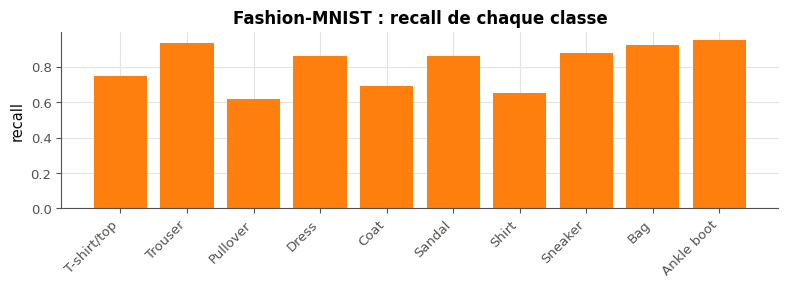

✅ Ex 29.8a : Exact !
✅ Ex 29.8b : Bien joué !
✅ Ex 29.8c : C'est ça !


In [23]:
if any(answer is ... or answer is None for answer in [mnist_8, drop_8, crossed_8]):
    print("⏳ Ex 29.8 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    acc_m8, conf_m8 = evaluate(MODEL_M, XM_TEST, YM_TEST)
    acc_f8, conf_f8 = evaluate(MODEL_F, XF_TEST, YF_TEST)
    acc_x8, conf_x8 = evaluate(MODEL_M, XF_TEST, YF_TEST)
    print(f"MNIST : accuracy {fr(acc_m8)} ; Fashion-MNIST : accuracy {fr(acc_f8)}, soit {fr(100 * (acc_m8 - acc_f8), 1)} points de moins")
    print(f"Le modèle MNIST sur Fashion-MNIST : accuracy {fr(acc_x8)} (le hasard : 0,1), confiance moyenne {fr(conf_x8)}")
    with torch.no_grad():
        pred_f8 = MODEL_F(torch.as_tensor(XF_TEST, dtype=torch.float32) / 255.0).argmax(1).numpy()
    recall_f8 = [float((pred_f8[YF_TEST == c] == c).mean()) for c in range(10)]
    plt.figure(figsize=(8, 3))
    plt.bar(wb.datasets.FASHION_CLASSES, recall_f8, color="tab:orange")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("recall")
    plt.title("Fashion-MNIST : recall de chaque classe")
    plt.tight_layout()
    plt.show()
    wb.check("29.8a", mnist_8)
    wb.check("29.8b", drop_8)
    wb.check("29.8c", crossed_8)

Dans tes notes : quelles classes de Fashion-MNIST le réseau reconnaît-il le moins bien (le graphique), et pourquoi (Q4 e) ? Que dit c) de la confiance d'un modèle hors de sa distribution d'entraînement ? Pourquoi le livre conseille-t-il Fashion-MNIST comme étape après MNIST ?

### Ex 29.9 — Prédire la chute d'accuracy en changeant de source de chiffres 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que devient un modèle MNIST face à d'autres chiffres manuscrits, et s'il s'en rend compte.  
**Prérequis :** Ex 29.8 · fiche §29.2, « Au-delà du livre : le décalage de distribution » · **Fil rouge :** MNIST · **Parcours :** R, M, C

scikit-learn fournit d'autres chiffres manuscrits : 1 797 images de 8 × 8 pixels, valeurs de 0 à 16 (`load_digits`). La cellule suivante les agrandit **telles quelles** à 28 × 28, valeurs de 0 à 255 (`digits_naive`, dans les outils) : même format que MNIST, mêmes dix classes. On les donne à `MODEL_M` (29.8), sans autre entraînement.

**Avant d'exécuter**, écris tes deux prédictions :
a) l'accuracy de `MODEL_M` sur ces chiffres : `"A"` plus de 0,7, `"B"` de 0,4 à 0,7, `"C"` moins de 0,4 ;
b) la **confiance moyenne** du modèle sur ces chiffres (pour chaque image, sa plus grande probabilité softmax ; puis la moyenne) reste-t-elle au-dessus de 0,6 ? `True` ou `False`.

La cellule d'expérience montre aussi quelques images des deux sources côte à côte, et n'affiche rien tant que tes deux prédictions ne sont pas écrites.

In [24]:
from sklearn.datasets import load_digits

DIGITS_9 = load_digits()                       # 1 797 digits of 8 x 8 pixels, values 0 to 16 (an UCI collection)
XD_9 = digits_naive(DIGITS_9.images)           # enlarged as they are to 28 x 28, 0 to 255: the MNIST format?
YD_9 = DIGITS_9.target

In [25]:
digits_9, confident_9 = "C", True

In [26]:
wb.record("29.9a", "C", mistakes={"ce sont bien des chiffres, mais ni cadrés ni dessinés comme ceux de MNIST : l'accuracy chute beaucoup plus": "A",
                                  "regarde l'accuracy mesurée : elle tombe sous 0,4": "B"})
wb.record("29.9b", True, mistakes={"un modèle ne sait pas qu'il sort de sa distribution : sa confiance reste élevée quand il se trompe": False})

WB_ANSWER {"hash": "4cd7bfc91aeaed76f6a899ed8ac81e453739734dea7ee9a2e71b944ef2a750b4", "id": "29.9a", "kind": "str", "mistakes": {"b28606473110ef6044c9a5660cc1dda754ffbe7d5f6e4ec17095e373db98b100": "ce sont bien des chiffres, mais ni cadrés ni dessinés comme ceux de MNIST : l'accuracy chute beaucoup plus", "fac5b4f2ff15342213a1a70b4b0e51741fe2e3a7adf5299bf6e29de12c272187": "regarde l'accuracy mesurée : elle tombe sous 0,4"}}
📝 Ex 29.9a : réponse enregistrée (str).
WB_ANSWER {"hash": "d473c141e36b329e41aa32938cb02acb2df09f955b7f5e85581187bd90401029", "id": "29.9b", "kind": "bool", "mistakes": {"1abd87808b778502d95b334838ca8cf5c31c4c2c974534b3e4b38c1fe91ea2e2": "un modèle ne sait pas qu'il sort de sa distribution : sa confiance reste élevée quand il se trompe"}}
📝 Ex 29.9b : réponse enregistrée (bool).


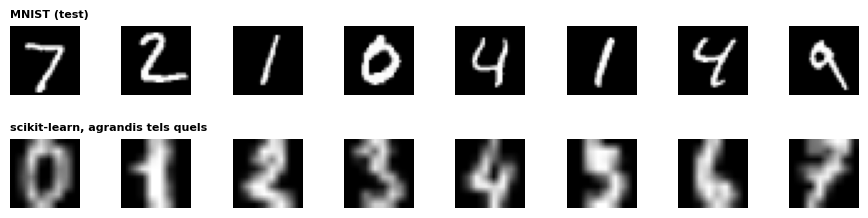

MNIST (test)          : accuracy 0,916, confiance moyenne 0,880
chiffres scikit-learn : accuracy 0,198, confiance moyenne 0,761
pixels moyens : 33,8 sur MNIST, 77,8 ici (0 à 255)
✅ Ex 29.9a : Bien joué !
✅ Ex 29.9b : C'est ça !


In [27]:
if any(answer is ... or answer is None for answer in [digits_9, confident_9]):
    print("⏳ Ex 29.9 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    show_digits([XM_TEST[:8], XD_9[:8]], ["MNIST (test)", "scikit-learn, agrandis tels quels"])
    acc_m9, conf_m9 = evaluate(MODEL_M, XM_TEST, YM_TEST)
    acc_d9, conf_d9 = evaluate(MODEL_M, XD_9, YD_9)
    print(f"MNIST (test)          : accuracy {fr(acc_m9)}, confiance moyenne {fr(conf_m9)}")
    print(f"chiffres scikit-learn : accuracy {fr(acc_d9)}, confiance moyenne {fr(conf_d9)}")
    print(f"pixels moyens : {fr(float(XM_TEST.mean()), 1)} sur MNIST, {fr(float(XD_9.mean()), 1)} ici (0 à 255)")
    wb.check("29.9a", digits_9)
    wb.check("29.9b", confident_9)

Dans tes notes : compare les deux rangées d'images. Qu'est-ce qui diffère, à part la taille d'origine (la place du chiffre dans l'image, l'épaisseur du trait, le flou) ? Pourquoi une confiance élevée sur des données décalées est-elle dangereuse en production ? 29.14 mesure ce que l'on récupère en préparant mieux les images.

### Ex 29.10 — torchvision.datasets et Hugging Face datasets : mêmes données, deux API 📦 ★★ ⏱️ 25 min
**Objectif :** charger un dataset du Hugging Face Hub à une révision fixée, le convertir en tableaux NumPy et le comparer à une autre source.  
**Prérequis :** ch. 20 et 23 (Dataset, DataLoader) · fiche §29.3.2 (encadré 🕰️, encadré 🧮) · **Fil rouge :** Fashion-MNIST · **Parcours :** R, M, C

La cellule suivante charge le split de test de Fashion-MNIST depuis le Hugging Face Hub, à une **révision** fixée (un commit du dépôt du dataset) : `load_dataset(nom, split="test", revision=...)`. Sans réseau, elle fabrique le même format depuis la copie du workbook et le dit. `wb.datasets.load_fashion_mnist`, lui, passe par `torchvision.datasets.FashionMNIST` (ou un miroir) et rend des tableaux NumPy.

**Contrat**
- `hf_to_numpy_10(split)` : depuis un split aux colonnes `"image"` (images PIL) et `"label"`, rend `(X, y)` : `X` en `uint8` de forme `(N, 28, 28)`, `y` en `int64` de forme `(N,)`, dans l'ordre du split ;
- `compare_10(Xa, ya, Xb, yb)` : un dictionnaire `{"same_shape", "same_labels", "same_pixels", "max_diff"}` ; `same_labels` exige autant de labels, égaux dans le même ordre ; `max_diff` est le plus grand écart absolu entre deux pixels (0 si identiques) ; si les formes diffèrent, `same_pixels` vaut `False` et `max_diff` vaut −1. Piège : en `uint8`, `3 - 10` vaut 249.

La cellule de vérification teste `compare_10` sur des cas fabriqués (un pixel modifié, des labels mélangés, des formes différentes), puis compare les deux sources de Fashion-MNIST et affiche les noms des classes de chacune.

Dans tes notes : les deux sources sont-elles identiques, pixel à pixel et dans le même ordre ? Les noms des classes sont-ils écrits pareil ? Pourquoi fixer `revision=` plutôt que prendre la dernière version ? Écris l'équivalent `torchvision.datasets.FashionMNIST(root, train=False, download=True)` et dis ce qu'il rend (des images PIL et des entiers, transformables par `transform=`).

In [28]:
# One version of Fashion-MNIST on the Hugging Face Hub, pinned to an exact revision (a commit of the dataset repository)
FASHION_REPO_10 = "zalando-datasets/fashion_mnist"
FASHION_REV_10 = "531be5e2ccc9dba0c201ad3ae567a4f3d16ecdd2"
import warnings
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")              # tqdm's notice about ipywidgets, printed once at import
        from datasets import Dataset, load_dataset
    try:
        with wb.datasets.quiet_huggingface():
            HF_10 = load_dataset(FASHION_REPO_10, split="test", revision=FASHION_REV_10,
                                 cache_dir=str(wb.datasets.cache_dir() / "hf"))
        SOURCE_10 = "le Hugging Face Hub"
    except Exception as exc:              # no network: the same format, built from the workbook copy
        from PIL import Image
        X_off10, y_off10 = wb.datasets.load_fashion_mnist("test")
        HF_10 = Dataset.from_dict({"image": [Image.fromarray(img) for img in X_off10], "label": y_off10.tolist()})
        SOURCE_10 = f"une copie locale au même format (Hub injoignable : {type(exc).__name__})"
except ImportError:
    HF_10, SOURCE_10 = None, "rien : la bibliothèque datasets est absente (pip install datasets)"
print(f"Fashion-MNIST (test) chargé depuis {SOURCE_10} : {HF_10}")

Fashion-MNIST (test) chargé depuis le Hugging Face Hub : Dataset({
    features: ['image', 'label'],
    num_rows: 10000
})


In [29]:
def hf_to_numpy_10(split):
    """(X, y) from a split of Hugging Face `datasets` with the columns "image" (PIL images) and "label": X uint8
    (N, 28, 28) and y int64 (N,), in the order of the split."""
    X = np.stack([np.asarray(img, dtype=np.uint8) for img in split["image"]])
    y = np.asarray(split["label"], dtype=np.int64)
    return X, y


def compare_10(Xa, ya, Xb, yb):
    """Compare two versions of the same images: a dict with "same_shape" (bool), "same_labels" (bool: as many labels,
    equal in the same order), "same_pixels" (bool, False when the shapes differ) and "max_diff" (int: the largest
    absolute difference between two pixels, 0 when identical, -1 when the shapes differ)."""
    Xa, Xb, ya, yb = np.asarray(Xa), np.asarray(Xb), np.asarray(ya), np.asarray(yb)
    same_shape = Xa.shape == Xb.shape
    same_labels = ya.shape == yb.shape and bool((ya == yb).all())
    max_diff = int(np.abs(Xa.astype(np.int64) - Xb.astype(np.int64)).max()) if same_shape else -1
    return {"same_shape": same_shape, "same_labels": same_labels, "same_pixels": max_diff == 0, "max_diff": max_diff}


with checked("29.10"):
    if HF_10 is None:
        print("⏳ Ex 29.10 : la bibliothèque datasets est absente : pip install datasets (déjà là sur Colab).")
        raise StopCheck
    X_hf10, y_hf10 = hf_to_numpy_10(HF_10)
    if not returned("29.10", "hf_to_numpy_10", X_hf10):
        raise StopCheck
    verdict("29.10", isinstance(X_hf10, np.ndarray) and X_hf10.shape == (len(HF_10), 28, 28) and X_hf10.dtype == np.uint8,
            "X : uint8 de forme (N, 28, 28).", f"X attendu uint8 (N, 28, 28), reçu {getattr(X_hf10, 'dtype', type(X_hf10))} {getattr(X_hf10, 'shape', '')}.")
    verdict("29.10", np.asarray(y_hf10).dtype == np.int64 and np.asarray(y_hf10).shape == (len(HF_10),),
            "y : int64 de forme (N,).", f"y attendu int64 (N,), reçu {np.asarray(y_hf10).dtype} {np.asarray(y_hf10).shape}.")
    if X_hf10.dtype == np.uint8:
        verdict("29.10", int(X_hf10[0].sum()) == int(np.asarray(HF_10[0]["image"], dtype=np.int64).sum()) and int(y_hf10[0]) == HF_10[0]["label"],
                "le premier exemple est bien le premier du split.", "le premier exemple ne correspond pas à HF_10[0] : garde l'ordre du split.")
    X_wb10, y_wb10 = wb.datasets.load_fashion_mnist("test")
    rng_10 = np.random.default_rng(10)
    X_a10 = X_wb10[:50].copy()
    r_10, c_10 = np.unravel_index(int(X_a10[3].argmax()), (28, 28))
    X_a10[3, r_10, c_10] -= 7                                           # its brightest pixel, darker by 7
    probe_10 = compare_10(X_a10, y_wb10[:50], X_wb10[:50], y_wb10[:50])   # the darker images first: 3 - 10 in uint8
    if not returned("29.10", "compare_10", probe_10):
        raise StopCheck
    keys_10 = {"same_shape", "same_labels", "same_pixels", "max_diff"}
    verdict("29.10", isinstance(probe_10, dict) and set(probe_10) == keys_10, "compare_10 rend un dict aux quatre clés.",
            f"attendu un dict aux clés {sorted(keys_10)}, reçu {probe_10!r:.120}.")
    verdict("29.10", probe_10.get("max_diff") == 7 and not bool(probe_10.get("same_pixels")),
            "un pixel plus sombre de 7 est vu (max_diff = 7, same_pixels False).",
            f"un pixel plus sombre de 7 : attendu max_diff = 7 et same_pixels False, reçu {probe_10.get('max_diff')} et "
            f"{probe_10.get('same_pixels')} (en uint8, 3 − 10 vaut 249 : convertis en entiers assez grands, int64, avant de soustraire).")
    shuffled_10 = compare_10(X_wb10[:50], y_wb10[:50], X_wb10[:50], rng_10.permutation(y_wb10[:50]))
    verdict("29.10", not bool(shuffled_10.get("same_labels")) and bool(shuffled_10.get("same_pixels")),
            "des labels mélangés sont vus.", "des labels mélangés (images identiques) : attendu same_labels False, same_pixels True.")
    other_10 = compare_10(X_wb10[:50], y_wb10[:50], X_wb10[:40], y_wb10[:40])
    verdict("29.10", not bool(other_10.get("same_shape")) and not bool(other_10.get("same_pixels")) and other_10.get("max_diff") == -1,
            "des formes différentes donnent max_diff = -1, sans erreur.",
            f"formes différentes : attendu same_shape et same_pixels False, max_diff -1, reçu {other_10}.")
    result_10 = compare_10(X_hf10, y_hf10, X_wb10, y_wb10)
    print(f"Hub (révision {FASHION_REV_10[:8]}) contre wb.datasets.load_fashion_mnist('test') : {result_10}")
    print("Noms des classes sur le Hub :", HF_10.features["label"].names if hasattr(HF_10.features["label"], "names") else "(pas de noms)")
    print("Noms des classes du workbook :", wb.datasets.FASHION_CLASSES)

✅ Ex 29.10 : X : uint8 de forme (N, 28, 28).
✅ Ex 29.10 : y : int64 de forme (N,).
✅ Ex 29.10 : le premier exemple est bien le premier du split.
✅ Ex 29.10 : compare_10 rend un dict aux quatre clés.
✅ Ex 29.10 : un pixel plus sombre de 7 est vu (max_diff = 7, same_pixels False).
✅ Ex 29.10 : des labels mélangés sont vus.
✅ Ex 29.10 : des formes différentes donnent max_diff = -1, sans erreur.
Hub (révision 531be5e2) contre wb.datasets.load_fashion_mnist('test') : {'same_shape': True, 'same_labels': True, 'same_pixels': True, 'max_diff': 0}
Noms des classes sur le Hub : ['T - shirt / top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Noms des classes du workbook : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### Ex 29.11 — Explorer le Hugging Face Hub et OpenML : chercher, filtrer, lire la licence 📦 ★★ ⏱️ 25 min
**Objectif :** chercher des datasets par programme sur le Hugging Face Hub et OpenML, et en lire la licence, la taille et la source.  
**Prérequis :** Ex 29.10 · fiche §29.4 (encadré 🕰️), §29.5 · **Parcours :** R, M, C

**Contrat**
- `search_hub_11(query, limit=5, api=None)` : les `limit` datasets du Hub **les plus téléchargés** que trouve `query`, du plus au moins téléchargé, dans un `DataFrame` aux colonnes `"id"`, `"downloads"` et `"licence"`. La licence est le `xxx` d'un tag `"license:xxx"`, recopié tel quel (`"inconnue"` s'il n'y a pas de tag). `api` est un `HfApi` (un nouveau si `None`) : `api.list_datasets(search=..., limit=..., sort="downloads")` rend des objets qui ont `.id`, `.downloads` et `.tags`.
- `openml_summary_11(data_id, fetch=None)` : un dictionnaire sur un dataset d'OpenML, lu dans `bunch = fetch(data_id=data_id, as_frame=True)` (`fetch` vaut par défaut `sklearn.datasets.fetch_openml`) : `"name"`, `"version"`, `"licence"` (dans `bunch.details`), `"rows"` et `"columns"` (de `bunch.frame`, cible comprise), `"target"` (`details["default_target_attribute"]`) et `"source"` (`details["original_data_url"]`, `None` s'il manque).

La cellule de vérification ne dépend pas du réseau : elle passe à tes fonctions un Hub et un OpenML **simulés** (`FakeHubApi`, `fake_fetch_openml`, dans les outils). La cellule suivante les lance pour de vrai si le réseau répond : la recherche `"penguins"` sur le Hub, puis Palmer Penguins sur OpenML (`data_id=42585`).

Dans tes notes : parmi les résultats du Hub, lesquels pourrais-tu utiliser dans un produit, d'après leur licence ? Que fais-tu d'un dataset sans licence ? Ouvre la page (la *dataset card*) du premier résultat : que dit-elle de la provenance des données ? Cherche deux datasets candidats pour ton projet final et note leur licence et leur taille.

In [30]:
def search_hub_11(query, limit=5, api=None):
    """A DataFrame of the `limit` most downloaded datasets of the Hugging Face Hub found by `query`, the most downloaded
    first, with the columns "id", "downloads" and "licence" (xxx of a tag "license:xxx", as it is; "inconnue" without one).
    `api` is an HfApi (a new one when None): use api.list_datasets(search=..., limit=..., sort="downloads")."""
    if api is None:
        from huggingface_hub import HfApi
        api = HfApi()
    rows = []
    for info in api.list_datasets(search=query, limit=limit, sort="downloads"):
        licences = [t.split(":", 1)[1] for t in (info.tags or []) if t.startswith("license:")]
        rows.append({"id": info.id, "downloads": info.downloads, "licence": licences[0] if licences else "inconnue"})
    return pd.DataFrame(rows, columns=["id", "downloads", "licence"])


def openml_summary_11(data_id, fetch=None):
    """A dict about a dataset of OpenML, from fetch(data_id=data_id, as_frame=True) (fetch: by default
    sklearn.datasets.fetch_openml): "name", "version", "licence", "rows" and "columns" (of bunch.frame, target
    included), "target" (details["default_target_attribute"]) and "source" (details["original_data_url"], None when
    absent)."""
    if fetch is None:
        from sklearn.datasets import fetch_openml as fetch
    bunch = fetch(data_id=data_id, as_frame=True)
    details = bunch.details
    rows, columns = bunch.frame.shape
    return {"name": details["name"], "version": details["version"], "licence": details.get("licence"),
            "rows": rows, "columns": columns, "target": details.get("default_target_attribute"),
            "source": details.get("original_data_url")}


with checked("29.11"):
    api_11 = FakeHubApi()
    found_11 = search_hub_11("penguin", limit=3, api=api_11)
    if not returned("29.11", "search_hub_11", found_11):
        raise StopCheck
    verdict("29.11", isinstance(found_11, pd.DataFrame) and list(found_11.columns) == ["id", "downloads", "licence"],
            "search_hub_11 rend un DataFrame aux colonnes id, downloads, licence.",
            f"attendu les colonnes ['id', 'downloads', 'licence'], reçu {list(getattr(found_11, 'columns', []))}.")
    want_11 = [("someone/penguins-images", 3400, "cc-by-nc-4.0"), ("demo/penguins-clean", 950, "cc0-1.0"),
               ("lab/penguins-gps", 610, "odbl")]
    got_11 = [tuple(r) for r in found_11[["id", "downloads", "licence"]].itertuples(index=False)] if len(found_11.columns) == 3 else []
    verdict("29.11", got_11 == want_11, "les 3 plus téléchargés, dans l'ordre, avec leur licence (sur un Hub simulé).",
            f"sur le Hub simulé, attendu {want_11}, reçu {got_11} (demande sort=\"downloads\" et limit à list_datasets).")
    none_11 = search_hub_11("sounds", limit=5, api=FakeHubApi())
    verdict("29.11", list(none_11["licence"]) == ["inconnue"], "un dataset sans tag de licence : « inconnue ».",
            f"pour un dataset sans tag license:, attendu « inconnue », reçu {list(none_11['licence'])}.")
    summary_11 = openml_summary_11(42585, fetch=fake_fetch_openml)
    if not returned("29.11", "openml_summary_11", summary_11):
        raise StopCheck
    frame_11 = fake_fetch_openml(42585).frame
    want_s11 = {"name": "penguins", "version": "1", "licence": "CC0", "rows": frame_11.shape[0],
                "columns": frame_11.shape[1], "target": "species", "source": "https://github.com/allisonhorst/palmerpenguins"}
    verdict("29.11", summary_11 == want_s11, "openml_summary_11 lit le nom, la version, la licence, la taille, la cible et la source.",
            f"sur un OpenML simulé, attendu {want_s11}, reçu {summary_11}.")

✅ Ex 29.11 : search_hub_11 rend un DataFrame aux colonnes id, downloads, licence.
✅ Ex 29.11 : les 3 plus téléchargés, dans l'ordre, avec leur licence (sur un Hub simulé).
✅ Ex 29.11 : un dataset sans tag de licence : « inconnue ».
✅ Ex 29.11 : openml_summary_11 lit le nom, la version, la licence, la taille, la cible et la source.


In [31]:
# Live, if the network answers (a few seconds; OpenML caches its files in the workbook cache)
if online("huggingface.co"):
    with checked("29.11"):
        print(search_hub_11("penguins", limit=5).to_string(index=False))
else:
    print("⏳ Hub injoignable : la recherche en direct est sautée (les vérifications ci-dessus suffisent).")
if online("www.openml.org"):
    with checked("29.11"):
        from sklearn.datasets import fetch_openml
        def fetch_cached_11(**kwargs):
            return fetch_openml(data_home=str(wb.datasets.cache_dir() / "openml"), **kwargs)
        print(openml_summary_11(42585, fetch=fetch_cached_11))
else:
    print("⏳ OpenML injoignable : le résumé en direct est sauté.")

                                                                   id  downloads  licence
                                                  SIH/palmer-penguins        372  cc0-1.0
clm-project/jev-boost-kn4-wtq-penguins-qwen3.6-35b-a3b-fp8-embeddings         61    other
                                       Penguin-Scrolls/PenguinScrolls         44 inconnue
                                                methodidacte/penguins         37  unknown
                        ashish-soni08/penguins-species-classification         21 inconnue
{'name': 'penguins', 'version': '1', 'licence': 'CC0', 'rows': 344, 'columns': 7, 'target': 'species', 'source': 'https://github.com/allisonhorst/palmerpenguins'}


## Partie B · Auditer, documenter, déjouer les pièges

Avant d'entraîner quoi que ce soit : profiler un dataset inconnu, traquer les doublons qui gonflent un score, mesurer un décalage de distribution, puis écrire la data card et le script de téléchargement de ton projet final. Le défi final rassemble tout sur un tableau qui cache huit défauts.

### Ex 29.12 — Profil express d'un dataset inconnu 📈 ★★ ⏱️ 20 min
**Objectif :** écrire en quelques lignes le profil de chaque colonne d'un tableau, et y lire ses défauts.  
**Prérequis :** ch. 12 (pandas) · 0A · fiche « Au-delà du livre : auditer un dataset » · **Parcours :** R, M, C

Adult (le recensement américain de 1994, `data/cards/adult.md`) est chargé dans `ADULT_12`.

**Contrat** de `profile_12(df)` : un `DataFrame` indexé par les noms des colonnes de `df` (dans leur ordre), aux colonnes `"type"` (`str` du dtype), `"manquants"` (le nombre de valeurs manquantes), `"part_manquants"` (leur part, entre 0 et 1), `"distinctes"` (le nombre de valeurs distinctes, sans les manquantes), `"mode"` (la valeur la plus fréquente) et `"part_mode"` (sa part parmi les valeurs présentes).

La cellule de vérification compare ton profil aux mesures de pandas et trace deux graphiques (la part de manquants et la part du mode, colonne par colonne). Reporte :
a) la colonne d'`ADULT_12` qui a le plus de valeurs manquantes ;
b) le nombre de lignes qui répètent une ligne précédente (`duplicated`) ;
c) la part de la classe majoritaire de la colonne `"class"`, à 2 décimales.

Dans tes notes : quelles colonnes sont presque constantes (une part du mode au-dessus de 0,9) ? Sont-elles inutiles pour autant ? Les doublons de b) sont-ils des erreurs, ou deux personnes qui se ressemblent ? Que vaut un modèle qui prédit toujours la classe majoritaire (✏️ 29.2) ?

In [32]:
ADULT_12 = wb.datasets.load_adult()     # the 1994 US census (48 842 people), data/cards/adult.md
ADULT_12.head(3)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K


✅ Ex 29.12 : une ligne par colonne, les six colonnes demandées.
✅ Ex 29.12 : « type » est juste pour les 15 colonnes.
✅ Ex 29.12 : « manquants » est juste pour les 15 colonnes.
✅ Ex 29.12 : « part_manquants » est juste pour les 15 colonnes.
✅ Ex 29.12 : « distinctes » est juste pour les 15 colonnes.
✅ Ex 29.12 : « part_mode » est juste pour les 15 colonnes.
✅ Ex 29.12 : le mode est la valeur la plus fréquente.


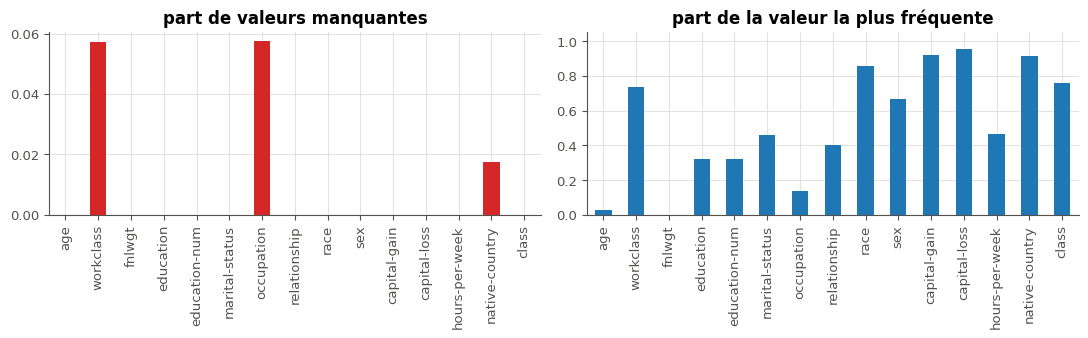

✅ Ex 29.12a : Parfait !
✅ Ex 29.12b : Bravo !
✅ Ex 29.12c : Exact !


In [33]:
def profile_12(df):
    """One row per column of df (same order, index = the column names), with the columns "type" (str of the dtype),
    "manquants" (the number of missing values), "part_manquants" (their share, 0 to 1), "distinctes" (the number of
    distinct values, missing ones excluded), "mode" (the most frequent value) and "part_mode" (its share among the
    values that are not missing)."""
    rows = {}
    for col in df.columns:
        s = df[col]
        counts = s.value_counts(dropna=True)
        rows[col] = {"type": str(s.dtype), "manquants": int(s.isna().sum()), "part_manquants": float(s.isna().mean()),
                     "distinctes": int(s.nunique(dropna=True)), "mode": counts.index[0],
                     "part_mode": float(counts.iloc[0] / counts.sum())}
    return pd.DataFrame.from_dict(rows, orient="index")


prof_12 = profile_12(ADULT_12)
most_missing_12 = prof_12["manquants"].idxmax()
duplicates_12 = int(ADULT_12.duplicated().sum())
majority_12 = round(float(ADULT_12["class"].value_counts(normalize=True).iloc[0]), 2)


with checked("29.12"):
    prof_c12 = profile_12(ADULT_12)
    if not returned("29.12", "profile_12", prof_c12):
        raise StopCheck
    cols_12 = ["type", "manquants", "part_manquants", "distinctes", "mode", "part_mode"]
    verdict("29.12", isinstance(prof_c12, pd.DataFrame) and list(prof_c12.columns) == cols_12
            and list(prof_c12.index) == list(ADULT_12.columns),
            "une ligne par colonne, les six colonnes demandées.",
            f"attendu l'index {list(ADULT_12.columns)[:3]}… et les colonnes {cols_12}, reçu {list(getattr(prof_c12, 'columns', []))}.")
    want_12 = pd.DataFrame({"type": ADULT_12.dtypes.astype(str), "manquants": ADULT_12.isna().sum(),
                            "part_manquants": ADULT_12.isna().mean(), "distinctes": ADULT_12.nunique(),
                            "part_mode": [float(ADULT_12[c].value_counts(normalize=True).iloc[0]) for c in ADULT_12.columns]})
    for field_12 in ["type", "manquants", "part_manquants", "distinctes", "part_mode"]:
        if field_12 == "type":
            bad_12 = [c for c in ADULT_12.columns if str(prof_c12.loc[c, field_12]) != want_12.loc[c, field_12]]
        else:
            bad_12 = [c for c in ADULT_12.columns
                      if not np.isclose(float(prof_c12.loc[c, field_12]), float(want_12.loc[c, field_12]), rtol=1e-9, atol=1e-12)]
        verdict("29.12", not bad_12, f"« {field_12} » est juste pour les {len(ADULT_12.columns)} colonnes.",
                f"« {field_12} » faux pour {', '.join(bad_12[:4])}{'…' if len(bad_12) > 4 else ''} "
                f"(par exemple {bad_12[0] if bad_12 else ''} : attendu {want_12.loc[bad_12[0], field_12] if bad_12 else ''}, "
                f"reçu {prof_c12.loc[bad_12[0], field_12] if bad_12 else ''}).")
    verdict("29.12", str(prof_c12.loc["sex", "mode"]) == str(ADULT_12["sex"].mode().iloc[0]), "le mode est la valeur la plus fréquente.",
            f"mode de « sex » : attendu {ADULT_12['sex'].mode().iloc[0]!r}, reçu {prof_c12.loc['sex', 'mode']!r}.")
    fig_12, axes_12 = plt.subplots(1, 2, figsize=(11, 3.5))
    prof_c12["part_manquants"].plot.bar(ax=axes_12[0], color="tab:red", title="part de valeurs manquantes")
    prof_c12["part_mode"].plot.bar(ax=axes_12[1], color="tab:blue", title="part de la valeur la plus fréquente")
    for ax_12 in axes_12:
        ax_12.set_ylim(0, 1.05 if ax_12 is axes_12[1] else None)
    plt.tight_layout()
    plt.show()
wb.check("29.12a", most_missing_12)
wb.check("29.12b", duplicates_12)
wb.check("29.12c", majority_12)

In [34]:
wb.record("29.12a", "occupation", mistakes={"workclass est juste derrière : compare les deux nombres de manquants": "workclass",
                                            "native-country en a beaucoup moins : regarde la colonne manquants": "native-country"})
wb.record("29.12b", 52, mistakes={"duplicated() marque chaque répétition, pas les deux lignes d'une paire": 104,
                                  "ADULT_12.duplicated() compte les lignes répétées : il y en a": 0})
wb.record("29.12c", 0.76, decimals=2, mistakes={"c'est la classe minoritaire (>50K)": 0.24})

WB_ANSWER {"hash": "d35c176e9483f0caf715931fc314297835c518c71823b2e5f34796e12a367f60", "id": "29.12a", "kind": "str", "mistakes": {"541e56fbf1d59d05a26c6cff410a0126852e8bfe9cf0e31ebdec82117f870961": "workclass est juste derrière : compare les deux nombres de manquants", "ca5983a9a3b872e4bc248d46c50f9cb8ed566f2e71cf00bd7efe279d9c449575": "native-country en a beaucoup moins : regarde la colonne manquants"}}
📝 Ex 29.12a : réponse enregistrée (str).
WB_ANSWER {"hash": "437cd9fdc173c2016cdf86d9604dc6cd1ccac3651246fd0dca0b47a0773bbf54", "id": "29.12b", "kind": "int", "magnitude": 1, "mistakes": {"2c83b75205ba01cd245b6697b27f3f14340e146cdeffc95cd22dec3c79f0d319": "ADULT_12.duplicated() compte les lignes répétées : il y en a", "f26f966f8ca506dd30ceaa4b5edae8849a19de526f83642125b6bb85833b4b5f": "duplicated() marque chaque répétition, pas les deux lignes d'une paire"}, "sign": 1}
📝 Ex 29.12b : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "034dd2d3a4a2284a646dae7d27d0a00316d0bdfd4

### Ex 29.13 — Un score trop beau pour être vrai : doublons entre entraînement et test 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver les trois fuites d'une évaluation et la corriger, en découpant par groupes.  
**Prérequis :** ch. 8 (découpage, validation) · fiche « Au-delà du livre : auditer un dataset » · 💼 29.E3 · **Parcours :** R, M, C

Un collègue a photographié 500 vêtements, chacun quatre fois (lumière et bruit un peu différents) : 2 000 images, `X_13`, leurs labels `Y_13`, et `GROUPS_13`, le numéro du vêtement de chaque image. Son évaluation, `evaluate_buggy_13` (cellule suivante), annonce une accuracy de test parfaite. Elle contient **trois** lignes fautives, trois façons de laisser le test influencer l'entraînement ou l'évaluation.

1. Écris dans `faulty_13` les lettres des lignes fautives (dans n'importe quel ordre).
2. Mesure la fuite principale : `shared_13`, le nombre de lignes de test du découpage de la ligne B dont le vêtement (`GROUPS_13`) apparaît aussi dans l'entraînement. Refais ce découpage avec les mêmes réglages : `train_test_split` rend les mêmes indices pour toute liste de même longueur, découpée avec le même `stratify` et le même `random_state`.
3. Écris `evaluate_fixed_13` selon sa docstring : mêmes sorties, sans les fuites.

La cellule de vérification lance aussi ta version sur un piège : un label tiré **au hasard** pour chaque vêtement. Rien n'est apprenable, une évaluation honnête doit tomber au niveau du hasard (environ 0,1). Puis elle espionne `PCA` et `KNeighborsClassifier` pendant un appel de ta version : quelles lignes voit chaque `fit`, chaque `score` ?

Dans tes notes : pour chaque ligne fautive, la fuite qu'elle crée. Laquelle explique presque tout l'écart ? Où trouve-t-on des quasi-doublons dans de vrais datasets (photos en rafale, plusieurs images d'un même patient, phrases traduites deux fois) ?

In [35]:
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier


def make_near_duplicates_13(n_sources=500, copies=4, seed=13):
    """Photos taken several times: each of n_sources Fashion-MNIST images appears `copies` times, each time with a
    slightly different brightness and a small noise. X uint8 (N, 28, 28), y (N,), groups (N,): the index of the
    source image of each row (the rows of a group are near-duplicates)."""
    Xs, ys = wb.datasets.load_fashion_mnist("train", n_sources, seed=seed)
    rng = np.random.default_rng(seed)
    n = n_sources * copies
    X = np.repeat(Xs.astype(float), copies, axis=0) * rng.uniform(0.9, 1.1, (n, 1, 1)) + rng.normal(0, 6, (n, 28, 28))
    return np.clip(np.rint(X), 0, 255).astype(np.uint8), np.repeat(ys, copies), np.repeat(np.arange(n_sources), copies)


X_13, Y_13, GROUPS_13 = make_near_duplicates_13()


# The evaluation to debug (do not change this cell: copy the function into the next one to fix it)
def evaluate_buggy_13(X, y, groups):
    X = X.reshape(len(X), -1) / 255.0                                                                    # A
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)         # B
    pca = PCA(n_components=40, random_state=0).fit(X)                                                    # C
    X_tr, X_te = pca.transform(X_tr), pca.transform(X_te)                                                # D
    best = max((1, 3, 5, 9), key=lambda k: KNeighborsClassifier(k).fit(X_tr, y_tr).score(X_te, y_te))   # E
    model = KNeighborsClassifier(best).fit(X_tr, y_tr)                                                   # F
    return best, model.score(X_te, y_te)                                                                 # G


best_b13, score_b13 = evaluate_buggy_13(X_13, Y_13, GROUPS_13)
print(f"{len(X_13)} images, {len(np.unique(GROUPS_13))} sources ; évaluation à corriger : k = {best_b13}, accuracy de test {fr(score_b13)}")

2000 images, 500 sources ; évaluation à corriger : k = 1, accuracy de test 1,000


In [36]:
faulty_13 = "BCE"
g_tr13, g_te13 = train_test_split(GROUPS_13, test_size=0.25, random_state=0, stratify=Y_13)   # the split of line B
shared_13 = int(np.isin(g_te13, g_tr13).sum())


def evaluate_fixed_13(X, y, groups):
    """evaluate_buggy_13 without its leaks (same returns: the chosen k, the test accuracy):
    - test split by groups: GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0);
    - k chosen on a validation part carved out of the training rows, also by groups (test_size=0.25, random_state=1);
    - the PCA fitted on the rows that train the model, never on the rows it is scored on;
    - at the end, k-NN with the chosen k refitted on all the training rows, scored once on the test rows."""
    X = X.reshape(len(X), -1) / 255.0
    train, test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups))
    fit, val = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1).split(X[train], y[train], groups[train]))
    fit, val = train[fit], train[val]
    pca = PCA(n_components=40, random_state=0).fit(X[fit])
    scores = {k: KNeighborsClassifier(k).fit(pca.transform(X[fit]), y[fit]).score(pca.transform(X[val]), y[val])
              for k in (1, 3, 5, 9)}
    best = max(scores, key=scores.get)
    pca = PCA(n_components=40, random_state=0).fit(X[train])
    model = KNeighborsClassifier(best).fit(pca.transform(X[train]), y[train])
    return best, model.score(pca.transform(X[test]), y[test])


wb.check("29.13a", faulty_13)
wb.check("29.13b", shared_13)
with checked("29.13"):
    out_13 = evaluate_fixed_13(X_13, Y_13, GROUPS_13)
    if not returned("29.13", "evaluate_fixed_13", out_13):
        raise StopCheck
    best_13, score_13 = out_13
    verdict("29.13", best_13 in (1, 3, 5, 9) and 0 <= score_13 <= 1, f"k = {best_13}, accuracy de test {fr(score_13)}.",
            f"attendu (k parmi 1, 3, 5, 9 ; une accuracy entre 0 et 1), reçu {out_13}.")
    # A trap: one random label per source image. Nothing can be learned, so an honest evaluation gives about 0.1;
    # a split that leaves near-duplicates on both sides recognises the copies and scores near 1.
    y_rand13 = np.random.default_rng(1).integers(0, 10, GROUPS_13.max() + 1)[GROUPS_13]
    _, score_rand13 = evaluate_fixed_13(X_13, y_rand13, GROUPS_13)
    _, score_rand_b13 = evaluate_buggy_13(X_13, y_rand13, GROUPS_13)
    verdict("29.13", score_rand13 < 0.3,
            f"labels tirés au hasard par source : {fr(score_rand13)} (le hasard), contre {fr(score_rand_b13)} pour la version fautive.",
            f"labels tirés au hasard par source : ta version obtient {fr(score_rand13)}, loin du hasard (0,1) : des copies "
            "d'une même source sont encore des deux côtés du découpage.")
    verdict("29.13", 0.5 < score_13 < score_b13 - 0.1, "sur les vraies données, l'accuracy honnête est nettement plus basse.",
            f"accuracy {fr(score_13)} : attendu nettement moins que les {fr(score_b13)} de la version fautive, et plus de 0,5.")
    # Spies on PCA and KNeighborsClassifier: which rows does each fit and each score see?
    _, events_13 = watch_leaks(evaluate_fixed_13, X_13, Y_13, GROUPS_13)
    scores_13 = [r for kind, r in events_13 if kind == "knn_score"]
    if not scores_13 or any(r is None for _, r in events_13):
        print("ℹ️ Ex 29.13 : ta fonction n'appelle pas PCA et KNeighborsClassifier du notebook sur des lignes reconnaissables : "
              "les vérifications ligne à ligne sont sautées.")
    else:
        test_13 = set(scores_13[-1].tolist())                   # the rows of the last score: the test
        groups_test13 = set(GROUPS_13[sorted(test_13)].tolist())
        verdict("29.13", not any(test_13 & set(r.tolist()) for kind, r in events_13 if kind == "pca_fit"),
                "la PCA n'est jamais ajustée sur des lignes de test.", "la PCA a vu des lignes de test pendant un fit (ligne C).")
        uses_13 = sum(1 for r in scores_13 if test_13 & set(r.tolist()))
        verdict("29.13", uses_13 == 1, "le test ne sert qu'une fois, à la fin.",
                f"le test a servi à {uses_13} scores : choisis k sur une validation, pas sur le test (ligne E).")
        verdict("29.13", not any(groups_test13 & set(GROUPS_13[r].tolist()) for kind, r in events_13 if kind == "knn_fit"),
                "aucun vêtement du test n'a servi à entraîner.", "des vêtements du test ont aussi servi à entraîner : découpe par groupes (ligne B).")
        overlap_13, last_fit_13 = False, None
        for kind, r in events_13:
            if kind == "knn_fit":
                last_fit_13 = r
            elif kind == "knn_score" and last_fit_13 is not None and not test_13 & set(r.tolist()):
                overlap_13 |= bool(set(GROUPS_13[r].tolist()) & set(GROUPS_13[last_fit_13].tolist()))
        verdict("29.13", not overlap_13, "la validation ne partage aucun vêtement avec les lignes qui entraînent.",
                "la validation partage des vêtements avec les lignes qui entraînent : découpe-la aussi par groupes.")

✅ Ex 29.13a : Bravo !
✅ Ex 29.13b : Exact !


✅ Ex 29.13 : k = 3, accuracy de test 0,728.


✅ Ex 29.13 : labels tirés au hasard par source : 0,092 (le hasard), contre 0,998 pour la version fautive.
✅ Ex 29.13 : sur les vraies données, l'accuracy honnête est nettement plus basse.
✅ Ex 29.13 : la PCA n'est jamais ajustée sur des lignes de test.
✅ Ex 29.13 : le test ne sert qu'une fois, à la fin.
✅ Ex 29.13 : aucun vêtement du test n'a servi à entraîner.
✅ Ex 29.13 : la validation ne partage aucun vêtement avec les lignes qui entraînent.


In [37]:
wb.record("29.13a", "BCE", mistakes={"il manque une ligne fautive : le découpage au hasard ignore GROUPS_13 : les copies d'une même photo tombent des deux côtés": "CE",
                     "il manque une ligne fautive : la PCA est ajustée sur toutes les lignes, test compris": "BE",
                     "il manque une ligne fautive : k est choisi sur le score de test, qui sert ensuite à juger le modèle": "BC",
                     "une ligne de trop : la ligne (A) est correcte ; relis ce qu'elle fait": "ABCE",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "BCDE",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "BCEF",
                     "une ligne de trop : la ligne (G) est correcte ; relis ce qu'elle fait": "BCEG",
                     "la ligne (A) est correcte, et il manque une ligne fautive : le découpage au hasard ignore GROUPS_13 : les copies d'une même photo tombent des deux côtés": "ACE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : le découpage au hasard ignore GROUPS_13 : les copies d'une même photo tombent des deux côtés": "CDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : le découpage au hasard ignore GROUPS_13 : les copies d'une même photo tombent des deux côtés": "CEF",
                     "la ligne (G) est correcte, et il manque une ligne fautive : le découpage au hasard ignore GROUPS_13 : les copies d'une même photo tombent des deux côtés": "CEG",
                     "la ligne (A) est correcte, et il manque une ligne fautive : la PCA est ajustée sur toutes les lignes, test compris": "ABE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : la PCA est ajustée sur toutes les lignes, test compris": "BDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : la PCA est ajustée sur toutes les lignes, test compris": "BEF",
                     "la ligne (G) est correcte, et il manque une ligne fautive : la PCA est ajustée sur toutes les lignes, test compris": "BEG",
                     "la ligne (A) est correcte, et il manque une ligne fautive : k est choisi sur le score de test, qui sert ensuite à juger le modèle": "ABC",
                     "la ligne (D) est correcte, et il manque une ligne fautive : k est choisi sur le score de test, qui sert ensuite à juger le modèle": "BCD",
                     "la ligne (F) réentraîne avec le k déjà choisi : le choix fait sur le test est à la ligne (E)": "BCF",
                     "la ligne (G) est correcte, et il manque une ligne fautive : k est choisi sur le score de test, qui sert ensuite à juger le modèle": "BCG"})
wb.record("29.13b", 500, mistakes={"compte les lignes de test dont le groupe apparaît aussi dans l'entraînement (np.isin), pas l'inverse": 0, "le test du découpage de la ligne B a 500 lignes : compte-les une par une, pas par groupe": 125})

WB_ANSWER {"hash": "7178baf32d182c6a553e878644c3b5490cfe5ac026c86966e30cd43c5fdf6c3f", "id": "29.13a", "kind": "str", "mistakes": {"0322a77575d1d3396d1de8fa9b44532bec7f96bde30faa07ff6a291cbea4ce1c": "il manque une ligne fautive : k est choisi sur le score de test, qui sert ensuite à juger le modèle", "20772286700dd7a45f90c788aae8e37a9e89af62d2c1a1001de378744468b1ed": "la ligne (F) est correcte, et il manque une ligne fautive : le découpage au hasard ignore GROUPS_13 : les copies d'une même photo tombent des deux côtés", "2a61628af39ff072dced14feed243886e62ae9185b335d9ea190687f81fc9979": "la ligne (D) est correcte, et il manque une ligne fautive : k est choisi sur le score de test, qui sert ensuite à juger le modèle", "36d4f4dfefef5cb47d887dbcccf5652f1333d21a8b670acae1234057a3d943c6": "une ligne de trop : la ligne (G) est correcte ; relis ce qu'elle fait", "670b9534a3b05aba4ee5a80d133d0a469e37cecfb424c8b949eaf70e081a1296": "la ligne (G) est correcte, et il manque une ligne fautive : le 

### Ex 29.14 — Décalage de distribution : un modèle MNIST face aux chiffres de scikit-learn 🔬 ★★★ ⏱️ 35 min
**Objectif :** mesurer ce que récupère une préparation fidèle des images, puis quelques exemples étiquetés, face à un décalage de distribution.  
**Prérequis :** Ex 29.9 · ch. 23 (fine-tuning) · fiche « Au-delà du livre : le décalage de distribution » · **Fil rouge :** MNIST · **Parcours :** R, M, C

En 29.9, les chiffres de scikit-learn, agrandis tels quels, ont dérouté `MODEL_M`. Or les images de MNIST suivent une recette précise : chaque chiffre est réduit pour tenir dans un carré de 20 × 20, puis placé dans l'image de 28 × 28 de sorte que son **centre de masse** soit au centre.

**Contrat** de `to_mnist_14(images, method)` : la docstring de la cellule suivante. Trois méthodes : `"naive"` (comme `digits_naive`), `"box"` (agrandir à 20 × 20, puis 4 pixels noirs de chaque côté) et `"center"` (`"box"`, puis chaque image décalée pour mettre son centre de masse au centre, `(13,5 ; 13,5)`).

La cellule de vérification contrôle les trois méthodes. L'expérience mesure ensuite :
1. l'accuracy de `MODEL_M` avec chaque méthode ;
2. l'accuracy après un fine-tuning du réseau sur $k$ chiffres étiquetés par classe ($k$ = 0, 1, 5, 20), mesurée sur les autres chiffres ;
3. une référence : un modèle simple entraîné sur les chiffres de scikit-learn eux-mêmes.

Dans tes notes : quelle étape de préparation rapporte le plus ? Combien d'exemples étiquetés faut-il pour approcher la référence ? Le décalage restant tient-il aux images (le décalage de covariables de la fiche) ou aux labels ? Que ferais-tu, dans ton projet final, si les données d'utilisation diffèrent de celles d'entraînement ?

In [38]:
from scipy import ndimage

In [39]:
def to_mnist_14(images, method="box"):
    """Digits of scikit-learn (N, 8, 8), values 0 to 16, converted to the MNIST format: uint8 (N, 28, 28), 0 to 255
    (values * 255 / 16, rounded with np.rint, clipped to [0, 255] at the very end):
    - "naive": the whole 8 x 8 image enlarged to 28 x 28 (F.interpolate, mode="bilinear", align_corners=False);
    - "box": enlarged to 20 x 20 the same way, then 4 black pixels added on each side (MNIST digits fit in 20 x 20);
    - "center": "box", then each image shifted (ndimage.shift, order=1, float values) so that its centre of mass
      (ndimage.center_of_mass) lands on the centre (13.5, 13.5)."""
    t = torch.as_tensor(np.asarray(images), dtype=torch.float32)[:, None] * 255.0 / 16.0
    if method == "naive":
        out = F.interpolate(t, size=(28, 28), mode="bilinear", align_corners=False)[:, 0].numpy()
    else:
        small = F.interpolate(t, size=(20, 20), mode="bilinear", align_corners=False)
        out = F.pad(small, (4, 4, 4, 4))[:, 0].numpy()
        if method == "center":
            shifted = []
            for img in out:
                cy, cx = ndimage.center_of_mass(img)
                shifted.append(ndimage.shift(img, (13.5 - cy, 13.5 - cx), order=1))
            out = np.array(shifted)
        elif method != "box":
            raise ValueError(f"unknown method {method!r}")
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


with checked("29.14"):
    few_14 = DIGITS_9.images[:20]
    naive_14 = to_mnist_14(few_14, "naive")
    if not returned("29.14", "to_mnist_14", naive_14):
        raise StopCheck
    verdict("29.14", isinstance(naive_14, np.ndarray) and naive_14.shape == (20, 28, 28) and naive_14.dtype == np.uint8,
            "uint8 de forme (N, 28, 28).", f"attendu uint8 (20, 28, 28), reçu {getattr(naive_14, 'dtype', type(naive_14))} {getattr(naive_14, 'shape', '')}.")
    same("29.14", "naive (comparé à digits_naive des outils)", naive_14.astype(float), digits_naive(few_14).astype(float), atol=1.0)
    box_14 = to_mnist_14(few_14, "box")
    border_14 = np.concatenate([box_14[:, :4].ravel(), box_14[:, -4:].ravel(), box_14[:, :, :4].ravel(), box_14[:, :, -4:].ravel()])
    verdict("29.14", border_14.max() == 0 and box_14[:, 4:24, 4:24].max() > 200,
            "box : un cadre noir de 4 pixels autour d'un chiffre de 20 × 20.",
            "box : attendu 4 pixels noirs de chaque côté et le chiffre agrandi au centre, en 20 × 20.")
    t_14 = torch.as_tensor(few_14, dtype=torch.float32)[:, None] * 255.0 / 16.0
    want_box_14 = np.clip(np.rint(F.interpolate(t_14, size=(20, 20), mode="bilinear", align_corners=False)[:, 0].numpy()), 0, 255)
    same("29.14", "box (le carré central de 20 × 20)", box_14[:, 4:24, 4:24].astype(float), want_box_14, atol=1.0)
    center_14 = to_mnist_14(few_14, "center")
    mass_14 = np.array([ndimage.center_of_mass(img.astype(float)) for img in center_14])
    verdict("29.14", np.abs(mass_14 - 13.5).max() < 0.5, "center : le centre de masse de chaque chiffre est au centre de l'image.",
            f"center : un centre de masse s'écarte de {fr(float(np.abs(mass_14 - 13.5).max()), 2)} pixel du centre (13,5 ; 13,5).")

✅ Ex 29.14 : uint8 de forme (N, 28, 28).
✅ Ex 29.14 : naive (comparé à digits_naive des outils) : un tableau (20, 28, 28), comme attendu.
✅ Ex 29.14 : box : un cadre noir de 4 pixels autour d'un chiffre de 20 × 20.
✅ Ex 29.14 : box (le carré central de 20 × 20) : un tableau (20, 20, 20), comme attendu.
✅ Ex 29.14 : center : le centre de masse de chaque chiffre est au centre de l'image.


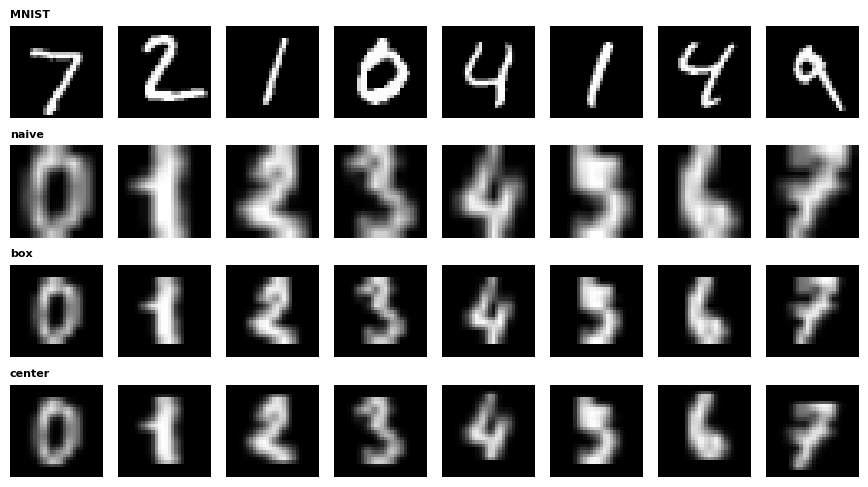

naive   : accuracy 0,198, confiance moyenne 0,761
box     : accuracy 0,576, confiance moyenne 0,716
center  : accuracy 0,661, confiance moyenne 0,745
 0 chiffres étiquetés par classe : accuracy 0,661
 1 chiffres étiquetés par classe : accuracy 0,793


 5 chiffres étiquetés par classe : accuracy 0,892
20 chiffres étiquetés par classe : accuracy 0,932


référence entraînée sur les chiffres de scikit-learn : accuracy 0,958


In [40]:
with checked("29.14"):
    # 1. The three conversions, the same network trained on MNIST (MODEL_M, 29.8): what does each step bring?
    methods_14 = ["naive", "box", "center"]
    converted_14 = {m: to_mnist_14(DIGITS_9.images, m) for m in methods_14}
    show_digits([XM_TEST[:8]] + [converted_14[m][:8] for m in methods_14], ["MNIST"] + methods_14)
    for m in methods_14:
        acc_14, conf_14 = evaluate(MODEL_M, converted_14[m], YD_9)
        print(f"{m:7s} : accuracy {fr(acc_14)}, confiance moyenne {fr(conf_14)}")

    # 2. Adapt with a few labelled digits of the new source (k per class), scored on the other digits
    rng_14 = np.random.default_rng(0)
    X_best14 = converted_14["center"]
    for k_14 in (0, 1, 5, 20):
        idx_14 = np.concatenate([rng_14.permutation(np.flatnonzero(YD_9 == c))[:k_14] for c in range(10)]).astype(int)
        rest_14 = np.setdiff1d(np.arange(len(YD_9)), idx_14)
        model_14 = fine_tune(MODEL_M, X_best14[idx_14], YD_9[idx_14]) if k_14 else MODEL_M
        print(f"{k_14:2d} chiffres étiquetés par classe : accuracy {fr(evaluate(model_14, X_best14[rest_14], YD_9[rest_14])[0])}")

    # 3. The reference: a model trained on the new source itself (logistic regression on the 8 x 8 pixels)
    from sklearn.linear_model import LogisticRegression
    Xa_14, Xb_14, ya_14, yb_14 = train_test_split(DIGITS_9.data, YD_9, test_size=0.25, random_state=0, stratify=YD_9)
    print(f"référence entraînée sur les chiffres de scikit-learn : accuracy {fr(LogisticRegression(max_iter=3000).fit(Xa_14, ya_14).score(Xb_14, yb_14))}")

### Ex 29.15 — Data card et script de téléchargement vérifié pour le projet final 🛠️ ★★★ ⏱️ 60 min
**Objectif :** écrire un téléchargement reproductible, vérifié par somme de contrôle, et la data card du dataset de ton projet final.  
**Prérequis :** Ex 29.6, 29.11 · fiche « Au-delà du livre : documenter et télécharger » (encadré 🧮) · **Parcours :** R, M, C

**Contrat**
- `sha256_15(path, chunk_size=1 << 20)` : la somme de contrôle SHA-256 d'un fichier (64 caractères hexadécimaux), lu **par morceaux** (`hashlib.sha256`, `update`, `hexdigest`) : un fichier de plusieurs gigaoctets ne tient pas en mémoire ;
- `download_verified_15(url, dest, sha256)` : si `dest` existe déjà avec la bonne somme, ne rien télécharger ; sinon télécharger dans `dest + ".part"` (par exemple avec `urllib.request.urlopen`), vérifier la somme, puis renommer en `dest` ; si la somme est fausse, supprimer le `.part` et lever `ValueError` (`dest` reste tel quel). Rendre `Path(dest)`.

La cellule de vérification « télécharge » des fichiers locaux (des URL `file://`) : arrivée intacte, lecture par morceaux, pas de nouveau téléchargement si le fichier est déjà là et intact, un nouveau s'il est abîmé, refus d'une somme fausse sans toucher à `dest`.

Puis remplis `CARD_15`, la data card du dataset de **ton projet final** : les six sections (Provenance, Contenu, Licence, Usage prévu, Limites et biais, Téléchargement), l'adresse de la source, et la somme SHA-256 de ton fichier (calculée avec `sha256_15` une fois le fichier téléchargé). Pour un dataset du Hugging Face Hub, note aussi la révision (`HfApi().dataset_info(nom).sha`) et télécharge avec `hf_hub_download(..., repo_type="dataset", revision=...)`. Modèle : les fiches de `data/cards/`. La vérification liste ce qui manque.

Dans tes notes : pourquoi télécharger dans un `.part` puis renommer ? Une somme de contrôle protège-t-elle contre un dataset qui change de contenu, contre un fichier corrompu, contre un dataset retiré ? Que doit faire ton script si la source disparaît ?

In [41]:
def sha256_15(path, chunk_size=1 << 20):
    """The SHA-256 of a file, 64 hexadecimal characters, read by chunks of chunk_size bytes (never all at once)."""
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download_verified_15(url, dest, sha256):
    """Download `url` to `dest`, unless dest already exists with the right SHA-256 (then nothing is downloaded).
    Download into dest + ".part" (for example with urllib.request.urlopen), check its SHA-256, then rename it to dest; on a wrong
    SHA-256, delete the .part file and raise ValueError (dest is left as it was). Return Path(dest)."""
    import shutil
    import urllib.request
    dest = Path(dest)
    if dest.exists() and sha256_15(dest) == sha256:
        return dest
    part = dest.with_name(dest.name + ".part")
    with urllib.request.urlopen(url) as response, open(part, "wb") as out:
        shutil.copyfileobj(response, out)
    got = sha256_15(part)
    if got != sha256:
        part.unlink()
        raise ValueError(f"SHA-256 inattendu pour {url} : {got} au lieu de {sha256}")
    part.replace(dest)
    return dest


PENGUINS_SHA_15 = sha256_15(ROOT / "data" / "penguins.csv")
CARD_15 = f"""# Palmer Penguins (exemple de data card)

## Provenance
Mesures de 344 manchots de trois espèces (Adélie, Chinstrap, Gentoo) sur trois îles de l'archipel Palmer (Antarctique),
de 2007 à 2009, par K. Gorman et la station Palmer (LTER). Paquet R palmerpenguins (A. Horst, A. Hill, K. Gorman) :
https://allisonhorst.github.io/palmerpenguins/ ; copie versionnée du workbook : data/penguins.csv.

## Contenu
344 lignes, 8 colonnes : espèce (le label), île, longueur et profondeur du bec (mm), longueur des nageoires (mm),
masse (g), sexe, année. 11 lignes ont des valeurs manquantes (dont 2 sans aucune mesure). Classes : 152 Adélie,
68 Chinstrap, 124 Gentoo.

## Licence
CC0 1.0 (domaine public) : tout usage, commercial compris ; citer les auteurs reste l'usage.

## Usage prévu
Apprendre la classification et l'exploration de données tabulaires. Pas d'usage scientifique sur les manchots en
général : trois îles et trois saisons seulement.

## Limites et biais
Petit (344 lignes), trois îles d'une seule région, trois années : un modèle ne vaut que pour cette population
(décalage de distribution ailleurs). Chinstrap est la classe rare (20 %) et n'a été mesurée que sur une île :
l'île et l'espèce sont confondues.

## Téléchargement
Copie versionnée du workbook, data/penguins.csv, SHA-256 {PENGUINS_SHA_15} :
download_verified_15((ROOT / "data" / "penguins.csv").as_uri(), "penguins.csv", sha256=PENGUINS_SHA_15)
"""


with checked("29.15"):
    src_15 = WORK_DIR / "source_15.bin"
    src_15.write_bytes(np.random.default_rng(15).bytes(3_000_000))           # a 3 MB file to "download"
    good_15 = hashlib.sha256(src_15.read_bytes()).hexdigest()
    got_15 = sha256_15(src_15)
    if not returned("29.15", "sha256_15", got_15):
        raise StopCheck
    verdict("29.15", got_15 == good_15, "sha256_15 rend la bonne somme de contrôle.",
            f"sha256_15 : attendu {good_15[:16]}…, reçu {str(got_15)[:16]}… (hexdigest(), sur tout le fichier).")
    dest_15 = WORK_DIR / "copy_15.bin"
    path_15 = download_verified_15(src_15.as_uri(), dest_15, good_15)
    verdict("29.15", Path(path_15) == dest_15 and dest_15.exists() and sha256_15(dest_15) == good_15,
            "un téléchargement vérifié arrive à destination.", "le fichier n'est pas arrivé intact dans dest, ou le chemin rendu est faux.")
    verdict("29.15", not dest_15.with_name(dest_15.name + ".part").exists(), "aucun fichier .part ne reste.",
            "un fichier .part reste après un téléchargement réussi : renomme-le en dest.")
    src_15.write_bytes(b"un autre contenu")                                   # the source changes...
    try:
        download_verified_15(src_15.as_uri(), dest_15, good_15)              # ...but dest is already there, intact
        skipped_15 = sha256_15(dest_15) == good_15
    except ValueError:
        skipped_15 = False
    verdict("29.15", skipped_15, "un fichier déjà présent et intact n'est pas téléchargé de nouveau.",
            "dest était déjà là avec la bonne somme : il ne fallait rien télécharger.")
    bad_15 = WORK_DIR / "bad_15.bin"
    try:
        download_verified_15(src_15.as_uri(), bad_15, good_15)
        raised_15 = False
    except ValueError:
        raised_15 = True
    verdict("29.15", raised_15 and not bad_15.exists() and not bad_15.with_name(bad_15.name + ".part").exists(),
            "une somme fausse lève ValueError et ne laisse aucun fichier.",
            "une somme fausse doit lever ValueError, sans laisser dest ni le .part.")
    real_sha15, sizes_15 = hashlib.sha256, []

    class SpySha15:
        """hashlib.sha256 that records the size of every piece of data it receives."""
        def __init__(self, data=b"", **kwargs):
            self.h = real_sha15(data, **kwargs)
            if data:
                sizes_15.append(len(data))

        def update(self, data):
            sizes_15.append(len(data))
            self.h.update(data)

        def __getattr__(self, name):
            return getattr(self.h, name)

    hashlib.sha256 = SpySha15
    try:
        small_15 = sha256_15(dest_15, chunk_size=1000)
    finally:
        hashlib.sha256 = real_sha15
    verdict("29.15", small_15 == good_15 and (not sizes_15 or max(sizes_15) <= 1000),
            "sha256_15 lit le fichier par morceaux de chunk_size octets.",
            f"avec chunk_size=1000, sha256_15 a reçu un morceau de {max(sizes_15, default=0)} octets : lis f.read(chunk_size) en boucle.")
    src2_15 = WORK_DIR / "source2_15.bin"
    src2_15.write_bytes(b"second fichier, " * 1000)
    good2_15 = hashlib.sha256(src2_15.read_bytes()).hexdigest()
    dest2_15 = WORK_DIR / "copy2_15.bin"
    dest2_15.write_bytes(b"un fichier abime")                          # dest exists but is corrupted
    download_verified_15(src2_15.as_uri(), dest2_15, good2_15)
    verdict("29.15", sha256_15(dest2_15) == good2_15, "un fichier déjà présent mais abîmé est téléchargé de nouveau.",
            "dest existait avec une mauvaise somme : il fallait le télécharger de nouveau (vérifie la somme, pas seulement l'existence).")
    dest3_15 = WORK_DIR / "copy3_15.bin"
    dest3_15.write_bytes(b"ancienne version")
    try:
        download_verified_15(src2_15.as_uri(), dest3_15, good_15)       # the source does not match this sum
    except ValueError:
        pass
    verdict("29.15", dest3_15.exists() and dest3_15.read_bytes() == b"ancienne version" and not dest3_15.with_name(dest3_15.name + ".part").exists(),
            "après un échec, dest reste tel quel.", "un téléchargement refusé a écrasé ou supprimé dest : télécharge dans le .part, et ne renomme qu'après vérification.")
    problems_15 = check_card(CARD_15)
    if "..." in CARD_15:
        print("⏳ Ex 29.15 : la data card de ton projet n'est pas encore remplie (il reste des « ... »).")
    else:
        verdict("29.15", not problems_15, "la data card a ses six sections, une source et une somme de contrôle.",
                "data card incomplète : " + " ; ".join(problems_15) + ".")

✅ Ex 29.15 : sha256_15 rend la bonne somme de contrôle.
✅ Ex 29.15 : un téléchargement vérifié arrive à destination.
✅ Ex 29.15 : aucun fichier .part ne reste.
✅ Ex 29.15 : un fichier déjà présent et intact n'est pas téléchargé de nouveau.
✅ Ex 29.15 : une somme fausse lève ValueError et ne laisse aucun fichier.
✅ Ex 29.15 : sha256_15 lit le fichier par morceaux de chunk_size octets.
✅ Ex 29.15 : un fichier déjà présent mais abîmé est téléchargé de nouveau.
✅ Ex 29.15 : après un échec, dest reste tel quel.
✅ Ex 29.15 : la data card a ses six sections, une source et une somme de contrôle.


### Ex 29.16 — Le dataset piégé : trouver les huit défauts 🏆 ★★★ ⏱️ 60 min
**Objectif :** auditer seul un tableau inconnu, y trouver huit défauts de types différents, puis le nettoyer.  
**Prérequis :** Ex 29.12, 29.13 · fiche « Au-delà du livre : auditer un dataset » (tableau des défauts) · **Parcours :** C

`FRUITS_16` décrit 1 230 fruits : un identifiant, six mesures, un pays, un code qualité, le label `fruit` (pomme, poire ou coing) et le découpage `split` déjà fait (`"train"` ou `"test"`). Il cache **huit défauts**, un de chaque sorte : doublons exacts, quasi-doublons entre entraînement et test, valeurs manquantes codées par un nombre, colonne sans information, colonne qui trahit le label, unités incohérentes, labels mal écrits, classe très rare.

Explore-le dans autant de cellules que tu veux (`describe`, `value_counts`, `duplicated`, `nunique`, `crosstab`…), puis réponds aux questions a) à h) de la cellule à compléter et écris `clean_16(df)`, qui rend une copie nettoyée.

La cellule de vérification contrôle tes huit réponses, puis ta copie nettoyée. L'expérience entraîne la même forêt aléatoire sur les données brutes et sur les données nettoyées, et compare leurs accuracies de test.

Dans tes notes : pour chaque défaut, la commande qui l'a révélé et ce qu'il aurait fait au modèle. Pourquoi l'accuracy baisse-t-elle après le nettoyage, alors que le modèle est meilleur ? Que mettrais-tu dans la section « Limites et biais » de la data card de ce dataset ?

In [42]:
FRUITS_16 = wb.datasets.make_trap_dataset()   # 1 230 rows, 11 columns; data/cards/trap.md
FRUITS_16.head()

,id_lot,poids_g,diametre_cm,sucre,acidite,couleur_r,couleur_v,pays,code_qualite,fruit,split
0,10256,193.8,7.33,12.47,0.593,159,110,France,QM-2,pomme,train
1,10636,150.3,7.70,12.16,0.509,209,107,France,QM-5,pomme,train
2,10024,145.2,6.89,11.31,0.541,178,180,France,QM-5,pomme,test
3,10621,135.1,7.42,14.15,0.393,176,142,France,QM-3,pomme,train
4,10619,192.7,6.40,9.99,0.337,151,158,France,QR-2,poire,train


In [43]:
df_16 = FRUITS_16
exact_16 = int(df_16.duplicated().sum())
train_16, test_16 = df_16[df_16["split"] == "train"], df_16[df_16["split"] == "test"]
key_16 = [c for c in df_16.columns if c not in ("id_lot", "split", "poids_g")]
pairs_16 = test_16.reset_index().merge(train_16[key_16 + ["poids_g"]], on=key_16, suffixes=("", "_train"))
pairs_16 = pairs_16[(pairs_16["poids_g"] - pairs_16["poids_g_train"]).abs() <= 1]
near_16 = int(pairs_16["index"].nunique())
print(df_16.describe().T[["min", "max"]])
missing_16 = "acidite"          # min = -999
constant_16 = "pays"            # a single distinct value
leak_16 = "code_qualite"        # its letter (M, R, C) is always the same for a given fruit
units_16 = "diametre_cm"        # a few values near 100: millimetres
valid_16 = {"pomme", "poire", "coing"}
labels_16 = int((~df_16["fruit"].isin(valid_16)).sum())
rare_16 = df_16.loc[df_16["fruit"].isin(valid_16), "fruit"].value_counts().idxmin()
print(pd.crosstab(df_16["code_qualite"].str[1], df_16["fruit"]))


def clean_16(df):
    """A cleaned copy of df: exact duplicates and the test near-duplicates of b) removed, missing values back to NaN,
    the columns of d) and e) dropped, the values of f) in a single unit, the labels of g) corrected (or the rows
    removed). df itself is not modified."""
    out = df.drop_duplicates().copy()
    train, test = out[out["split"] == "train"], out[out["split"] == "test"]
    key = [c for c in out.columns if c not in ("id_lot", "split", "poids_g")]
    pairs = test.reset_index().merge(train[key + ["poids_g"]], on=key, suffixes=("", "_train"))
    near = pairs.loc[(pairs["poids_g"] - pairs["poids_g_train"]).abs() <= 1, "index"].unique()
    out = out.drop(index=near)
    out["acidite"] = out["acidite"].replace(-999.0, np.nan)
    out = out.drop(columns=["pays", "code_qualite"])
    out.loc[out["diametre_cm"] > 30, "diametre_cm"] /= 10
    fixed = out["fruit"].str.strip().str.lower().replace({"pome": "pomme", "pommes": "pomme", "poir": "poire",
                                                           "coings": "coing"})
    out["fruit"] = fixed
    return out[out["fruit"].isin(["pomme", "poire", "coing"])].reset_index(drop=True)


wb.check("29.16a", exact_16)
wb.check("29.16b", near_16)
wb.check("29.16c", missing_16)
wb.check("29.16d", constant_16)
wb.check("29.16e", leak_16)
wb.check("29.16f", units_16)
wb.check("29.16g", labels_16)
wb.check("29.16h", rare_16)
with checked("29.16"):
    before_16 = FRUITS_16.copy()
    clean_c16 = clean_16(FRUITS_16)
    if not returned("29.16", "clean_16", clean_c16):
        raise StopCheck
    verdict("29.16", FRUITS_16.equals(before_16), "le tableau d'origine n'a pas été modifié.",
            "clean_16 a modifié FRUITS_16 : travaille sur une copie (df.copy()).")
    answers_16 = wb.datasets.trap_dataset_answers()
    gone_16 = [c for c in (answers_16["constant_column"], answers_16["leaking_column"]) if c in clean_c16.columns]
    verdict("29.16", not gone_16, "les colonnes inutile et fuyante ont disparu.", f"colonnes encore présentes : {gone_16}.")
    cols_c16 = [c for c in clean_c16.columns if c != "id_lot"]
    verdict("29.16", not clean_c16[cols_c16].duplicated().any(), "plus aucun doublon exact.",
            f"{int(clean_c16[cols_c16].duplicated().sum())} ligne(s) encore en double.")
    verdict("29.16", not (clean_c16["acidite"] == -999).any(), "plus de −999 dans acidite.",
            "il reste des −999 dans acidite : remplace-les par NaN (ou retire ces lignes).")
    verdict("29.16", clean_c16["diametre_cm"].max() < 30, "les diamètres sont tous en centimètres.",
            f"un diamètre vaut encore {fr(float(clean_c16['diametre_cm'].max()), 1)} : convertis les millimètres.")
    verdict("29.16", set(clean_c16["fruit"]) <= {"pomme", "poire", "coing"}, "tous les labels sont valides.",
            f"labels encore invalides : {sorted(set(clean_c16['fruit']) - {'pomme', 'poire', 'coing'})}.")
    if "id_lot" in clean_c16.columns:   # each label of the cleaned table is the fruit of its row (no typo sent to another fruit)
        truth_16 = FRUITS_16.drop_duplicates("id_lot").set_index("id_lot")["code_qualite"].str[1].map(
            {"M": "pomme", "R": "poire", "C": "coing"})
        wrong_16 = int((clean_c16["fruit"].to_numpy() != truth_16.reindex(clean_c16["id_lot"]).to_numpy()).sum())
        verdict("29.16", wrong_16 == 0, "chaque label corrigé est bien le fruit de sa ligne.",
                f"{wrong_16} label(s) corrigé(s) vers un autre fruit : une faute de frappe garde le fruit qu'elle écorche.")
    tr_c16, te_c16 = clean_c16[clean_c16["split"] == "train"], clean_c16[clean_c16["split"] == "test"]
    key_c16 = [c for c in clean_c16.columns if c not in ("id_lot", "split", "poids_g")]
    left_c16 = te_c16.merge(tr_c16[key_c16], on=key_c16)
    verdict("29.16", len(left_c16) == 0, "aucun quasi-doublon de l'entraînement ne reste dans le test.",
            f"{len(left_c16)} ligne(s) de test ont encore leur quasi-doublon dans l'entraînement.")
    verdict("29.16", len(clean_c16) >= 1150, f"{len(clean_c16)} lignes gardées sur {len(FRUITS_16)}.",
            f"seulement {len(clean_c16)} lignes gardées : as-tu jeté plus que les défauts ?")

                  min        max
id_lot       10000.00  20016.000
poids_g         94.80    385.600
diametre_cm      5.13    100.300
sucre            5.54     15.620
acidite       -999.00      1.099
couleur_r       12.00    255.000
couleur_v       26.00    254.000
fruit         POMME  Poire  coing  poir  poire  poire   pome  pomme  pommes
code_qualite                                                               
C                 0      0     24     0      0       0     0      0       0
M                 2      0      0     0      0       0     3    712       2
R                 0      1      0     1    483       2     0      0       0
✅ Ex 29.16a : C'est ça !
✅ Ex 29.16b : Parfait !
✅ Ex 29.16c : Bravo !
✅ Ex 29.16d : Exact !
✅ Ex 29.16e : Bien joué !
✅ Ex 29.16f : C'est ça !
✅ Ex 29.16g : Parfait !
✅ Ex 29.16h : Bravo !
✅ Ex 29.16 : le tableau d'origine n'a pas été modifié.
✅ Ex 29.16 : les colonnes inutile et fuyante ont disparu.
✅ Ex 29.16 : plus aucun doublon exact.
✅ Ex 29.16 : p

In [44]:
answers_r16 = wb.datasets.trap_dataset_answers()
wb.record("29.16a", answers_r16["exact_duplicates"], mistakes={"duplicated() ne compte que les répétitions, pas la première ligne de chaque paire": 26})
wb.record("29.16b", answers_r16["near_duplicates"], mistakes={"compte chaque ligne de test une seule fois, même si elle a deux jumelles dans l'entraînement": 18})
wb.record("29.16c", answers_r16["missing_code_column"], mistakes={"poids_g n'a pas de valeur aberrante négative : regarde les minimums de describe()": "poids_g"})
wb.record("29.16d", answers_r16["constant_column"], mistakes={"id_lot change à chaque ligne : c'est un identifiant, pas une colonne constante": "id_lot"})
wb.record("29.16e", answers_r16["leaking_column"], mistakes={"les mesures prédisent le fruit honnêtement : cherche une colonne qui le recopie": "couleur_r"})
wb.record("29.16f", answers_r16["units_column"], mistakes={"le poids varie de 95 à 386 g, sans saut d'unité : regarde le maximum des diamètres": "poids_g"})
wb.record("29.16g", answers_r16["invalid_labels"], mistakes={"« poire » suivi d'une espace n'est pas « poire » : value_counts() les sépare": 9})
wb.record("29.16h", answers_r16["rare_class"], mistakes={"compte seulement les labels bien écrits : la poire est loin d'être rare": "poire"})

WB_ANSWER {"hash": "988750eb88167873ce4fd8e481150a743e20356af17a16c17478d841c940e354", "id": "29.16a", "kind": "int", "magnitude": 1, "mistakes": {"027228d75d2d8378eba9f10f072c06c6e2c33b1088b8b704c4a3db4f0318ac63": "duplicated() ne compte que les répétitions, pas la première ligne de chaque paire"}, "sign": 1}
📝 Ex 29.16a : réponse enregistrée (int).
WB_ANSWER {"hash": "9c3268b236615d0e1d80348d05ee463c6109e973a4b771f07076dc67d4f0da92", "id": "29.16b", "kind": "int", "magnitude": 1, "mistakes": {"85d445192469a74b8643ed7d17ecd972dc725e685e18d54cada76d276edc00c2": "compte chaque ligne de test une seule fois, même si elle a deux jumelles dans l'entraînement"}, "sign": 1}
📝 Ex 29.16b : réponse enregistrée (int).
WB_ANSWER {"hash": "f3a325fb819d1c472eb56fa4f51ff4e14fe2d965ea4981ac7ad23da6fa112e49", "id": "29.16c", "kind": "str", "mistakes": {"2b0f8d0498f2ba39e0b4acb8e8b1d91ab0d17d29bf8b785fa16021ea644c7a28": "poids_g n'a pas de valeur aberrante négative : regarde les minimums de describe()"}

In [45]:
# What the defects change: the same forest, trained on "train" and scored on "test", before and after cleaning
from sklearn.ensemble import RandomForestClassifier


def score_16(df, columns):
    """Accuracy on the "test" rows of a random forest trained on the "train" rows (missing values set to -1)."""
    data = df.copy()
    X = pd.get_dummies(data[columns], dtype=float).fillna(-1)
    train, test = data["split"] == "train", data["split"] == "test"
    forest = RandomForestClassifier(n_estimators=100, random_state=0).fit(X[train], data.loc[train, "fruit"])
    return forest.score(X[test], data.loc[test, "fruit"])


with checked("29.16"):
    if (clean_16(FRUITS_16)["split"] == "test").sum() == 0:
        print("❌ Ex 29.16 : clean_16 ne garde aucune ligne de test : l'expérience est impossible.")
        raise StopCheck
    dirty_cols_16 = [c for c in FRUITS_16.columns if c not in ("id_lot", "split", "fruit")]
    clean_e16 = clean_16(FRUITS_16)
    clean_cols_16 = [c for c in clean_e16.columns if c not in ("id_lot", "split", "fruit")]
    print(f"données brutes, toutes les colonnes : accuracy {fr(score_16(FRUITS_16, dirty_cols_16))}")
    print(f"données nettoyées                   : accuracy {fr(score_16(clean_e16, clean_cols_16))}")

données brutes, toutes les colonnes : accuracy 0,991
données nettoyées                   : accuracy 0,967


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu charger un même dataset par deux API et vérifier qu'elles rendent les mêmes données ?
2. Sais-tu dire, en lisant sa page, si un dataset peut servir à ton projet (licence, provenance, retraits) ?
3. Sais-tu repérer une fuite entre entraînement et test, et découper par groupes ?

**Avant le checkpoint** : choisis le dataset de ton projet final, avec sa data card et un téléchargement vérifié (🛠️ 29.15).

**Pour aller plus loin** : Gebru et coll., « Datasheets for Datasets », et l'article de Northcutt et coll. sur les erreurs de labels des benchmarks, cités dans la fiche. La suite : le checkpoint de la partie VI, puis le projet final.